In [2]:

import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df = iris.frame
iris.target_names
df["species"] = df["target"].map(
    {0: "setosa", 1: "versicolor", 2: "virginica"}
)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


df.groupby("species")[iris.feature_names].agg(["mean","median","var","std","min","max"]).round(3)





sepal length (cm)                                sepal width (cm)  \
                        mean median    var    std  min  max             mean   
species                                                                        
setosa                 5.006    5.0  0.124  0.352  4.3  5.8            3.428   
versicolor             5.936    5.9  0.266  0.516  4.9  7.0            2.770   
virginica              6.588    6.5  0.404  0.636  4.9  7.9            2.974   

                                          petal length (cm)                \
           median    var    std  min  max              mean median    var   
species                                                                     
setosa        3.4  0.144  0.379  2.3  4.4             1.462   1.50  0.030   
versicolor    2.8  0.098  0.314  2.0  3.4             4.260   4.35  0.221   
virginica     3.0  0.104  0.322  2.2  3.8             5.552   5.55  0.305   

                            petal width (cm)                                 
              std  min  max             mean median    var    std  min  max  
species                                                                      
setosa      0.174  1.0  1.9            0.246    0.2  0.011  0.105  0.1  0.6  
versicolor  0.470  3.0  5.1            1.326    1.3  0.039  0.198  1.0  1.8  
virginica   0.552  4.5  6.9            2.026    2.0  0.075  0.275  1.4  2.5

In [3]:
def Q1(x):
    return x.quantile(0.25)

def Q2(x):
    return x.quantile(0.50)

def Q3(x):
    return x.quantile(0.75)

def IQR(x):
    return Q3(x) - Q1(x)

df.groupby("species")[iris.feature_names].agg([Q1, Q2, Q3, IQR]).round(3)

sepal length (cm)                  sepal width (cm)              \
                          Q1   Q2   Q3    IQR               Q1   Q2     Q3   
species                                                                      
setosa                 4.800  5.0  5.2  0.400            3.200  3.4  3.675   
versicolor             5.600  5.9  6.3  0.700            2.525  2.8  3.000   
virginica              6.225  6.5  6.9  0.675            2.800  3.0  3.175   

                  petal length (cm)                     petal width (cm)       \
              IQR                Q1    Q2     Q3    IQR               Q1   Q2   
species                                                                         
setosa      0.475               1.4  1.50  1.575  0.175              0.2  0.2   
versicolor  0.475               4.0  4.35  4.600  0.600              1.2  1.3   
virginica   0.375               5.1  5.55  5.875  0.775              1.8  2.0   

                      
             Q3  IQR  
species               
setosa      0.3  0.1  
versicolor  1.5  0.3  
virginica   2.3  0.5

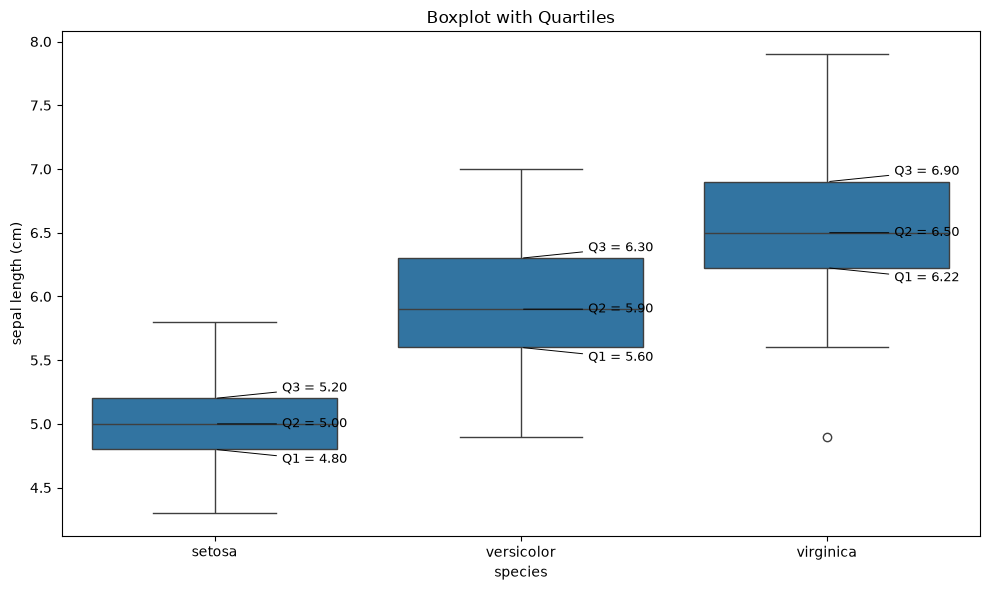

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

feature = "sepal length (cm)"

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="species", y=feature, ax=ax)

for i, species in enumerate(df["species"].unique()):
    values = df.loc[df["species"] == species, feature]

    q1 = values.quantile(0.25)
    q2 = values.quantile(0.50)
    q3 = values.quantile(0.75)

    labels = [
        (q1, f"Q1 = {q1:.2f}", -0.08),
        (q2, f"Q2 = {q2:.2f}", 0),
        (q3, f"Q3 = {q3:.2f}", 0.08)
    ]

    for value, label, offset in labels:
        ax.annotate(
            label,
            xy=(i, value),
            xytext=(i + 0.22, value + offset),
            fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.7),
            va="center"
        )

ax.set_title("Boxplot with Quartiles")
plt.tight_layout()
plt.show()

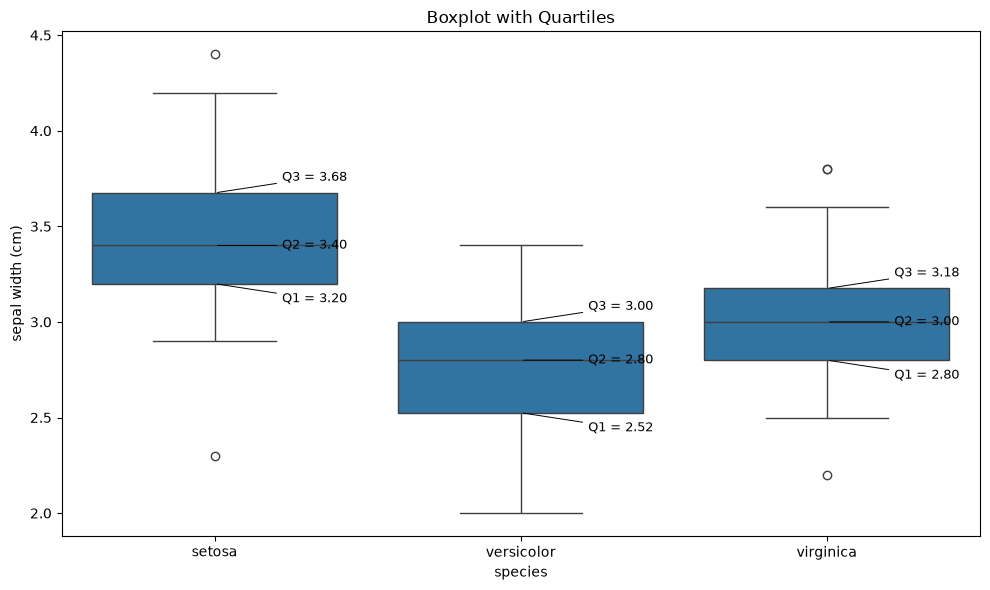

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

feature = "sepal width (cm)"

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="species", y=feature, ax=ax)

for i, species in enumerate(df["species"].unique()):
    values = df.loc[df["species"] == species, feature]

    q1 = values.quantile(0.25)
    q2 = values.quantile(0.50)
    q3 = values.quantile(0.75)

    labels = [
        (q1, f"Q1 = {q1:.2f}", -0.08),
        (q2, f"Q2 = {q2:.2f}", 0),
        (q3, f"Q3 = {q3:.2f}", 0.08)
    ]

    for value, label, offset in labels:
        ax.annotate(
            label,
            xy=(i, value),
            xytext=(i + 0.22, value + offset),
            fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.7),
            va="center"
        )

ax.set_title("Boxplot with Quartiles")
plt.tight_layout()
plt.show()

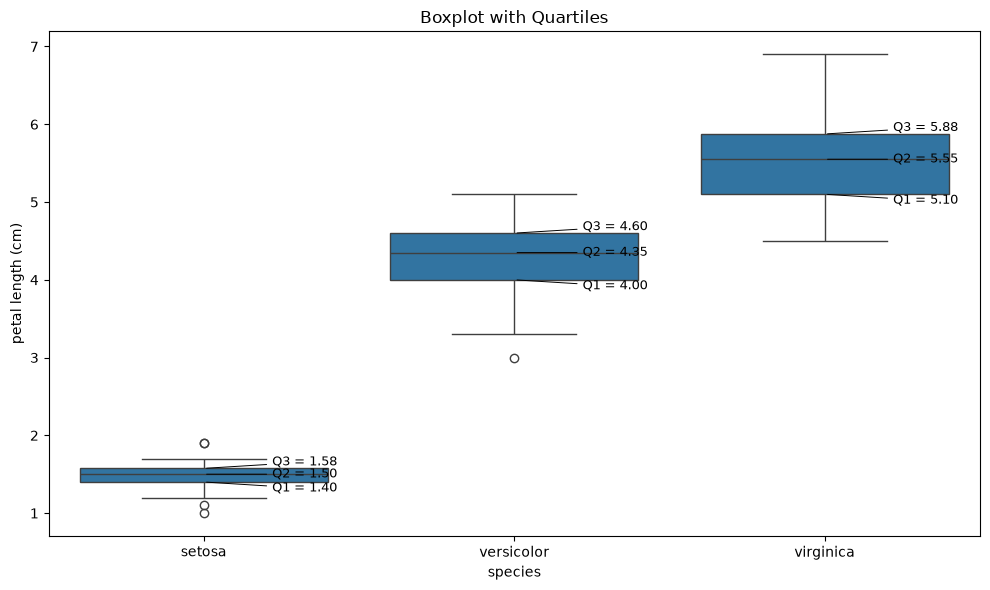

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

feature = "petal length (cm)"

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="species", y=feature, ax=ax)

for i, species in enumerate(df["species"].unique()):
    values = df.loc[df["species"] == species, feature]

    q1 = values.quantile(0.25)
    q2 = values.quantile(0.50)
    q3 = values.quantile(0.75)

    labels = [
        (q1, f"Q1 = {q1:.2f}", -0.08),
        (q2, f"Q2 = {q2:.2f}", 0),
        (q3, f"Q3 = {q3:.2f}", 0.08)
    ]

    for value, label, offset in labels:
        ax.annotate(
            label,
            xy=(i, value),
            xytext=(i + 0.22, value + offset),
            fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.7),
            va="center"
        )

ax.set_title("Boxplot with Quartiles")
plt.tight_layout()
plt.show()

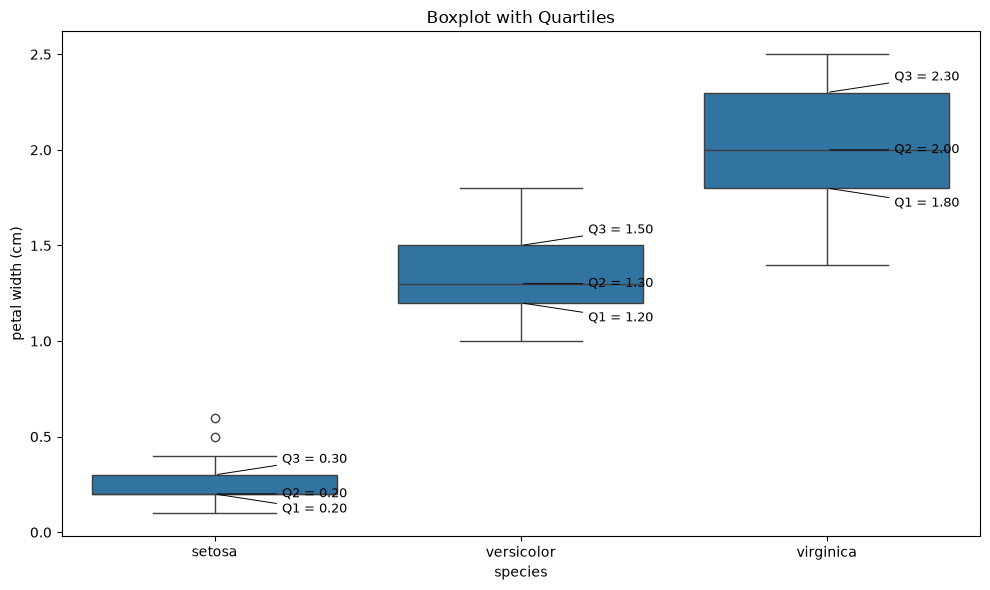

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

feature = "petal width (cm)"

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="species", y=feature, ax=ax)

for i, species in enumerate(df["species"].unique()):
    values = df.loc[df["species"] == species, feature]

    q1 = values.quantile(0.25)
    q2 = values.quantile(0.50)
    q3 = values.quantile(0.75)

    labels = [
        (q1, f"Q1 = {q1:.2f}", -0.08),
        (q2, f"Q2 = {q2:.2f}", 0),
        (q3, f"Q3 = {q3:.2f}", 0.08)
    ]

    for value, label, offset in labels:
        ax.annotate(
            label,
            xy=(i, value),
            xytext=(i + 0.22, value + offset),
            fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.7),
            va="center"
        )

ax.set_title("Boxplot with Quartiles")
plt.tight_layout()
plt.show()

In [8]:
from IPython.display import display
import pandas as pd

features = iris.feature_names

colors = {
    "sepal length (cm)": "#FF9999",
    "sepal width (cm)": "#99CCFF",
    "petal length (cm)": "#99E6B3",
    "petal width (cm)": "#D9B3FF"
}

# پیدا کردن تمام نمونه‌هایی که حداقل یک ویژگی پرت دارند
outlier_cells = {}

for species in df["species"].unique():
    group = df[df["species"] == species]

    for feature in features:
        q1 = group[feature].quantile(0.25)
        q3 = group[feature].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        mask = (group[feature] < lower) | (group[feature] > upper)

        for idx in group[mask].index:
            outlier_cells[(idx, feature)] = colors[feature]

# ساخت جدول شامل نمونه‌هایی که در حداقل یک ویژگی پرت هستند
rows = sorted(set(idx for idx, feature in outlier_cells))
table = df.loc[rows, ["species"] + features].copy()

def highlight_all_outliers(data):
    styles = pd.DataFrame("", index=data.index, columns=data.columns)

    for (idx, feature), color in outlier_cells.items():
        styles.loc[idx, feature] = (
            f"background-color: {color}; "
            "color: #222222; font-weight: bold;"
        )

    return styles

display(
    table.style
    .format({feature: "{:.2f}" for feature in features})
    .apply(highlight_all_outliers, axis=None)
    .set_properties(**{
        "text-align": "center",
        "padding": "8px",
        "border": "1px solid #dddddd"
    })
    .set_table_styles([{
        "selector": "th",
        "props": [
            ("background-color", "#37474F"),
            ("color", "white"),
            ("text-align", "center"),
            ("padding", "10px")
        ]
    }])
    .set_caption("Iris Dataset — Outlier Analysis")
)

,species,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
13,setosa,4.30,3.00,1.10,0.10
15,setosa,5.70,4.40,1.50,0.40
22,setosa,4.60,3.60,1.00,0.20
23,setosa,5.10,3.30,1.70,0.50
24,setosa,4.80,3.40,1.90,0.20
41,setosa,4.50,2.30,1.30,0.30
43,setosa,5.00,3.50,1.60,0.60
44,setosa,5.10,3.80,1.90,0.40
98,versicolor,5.10,2.50,3.00,1.10
106,virginica,4.90,2.50,4.50,1.70


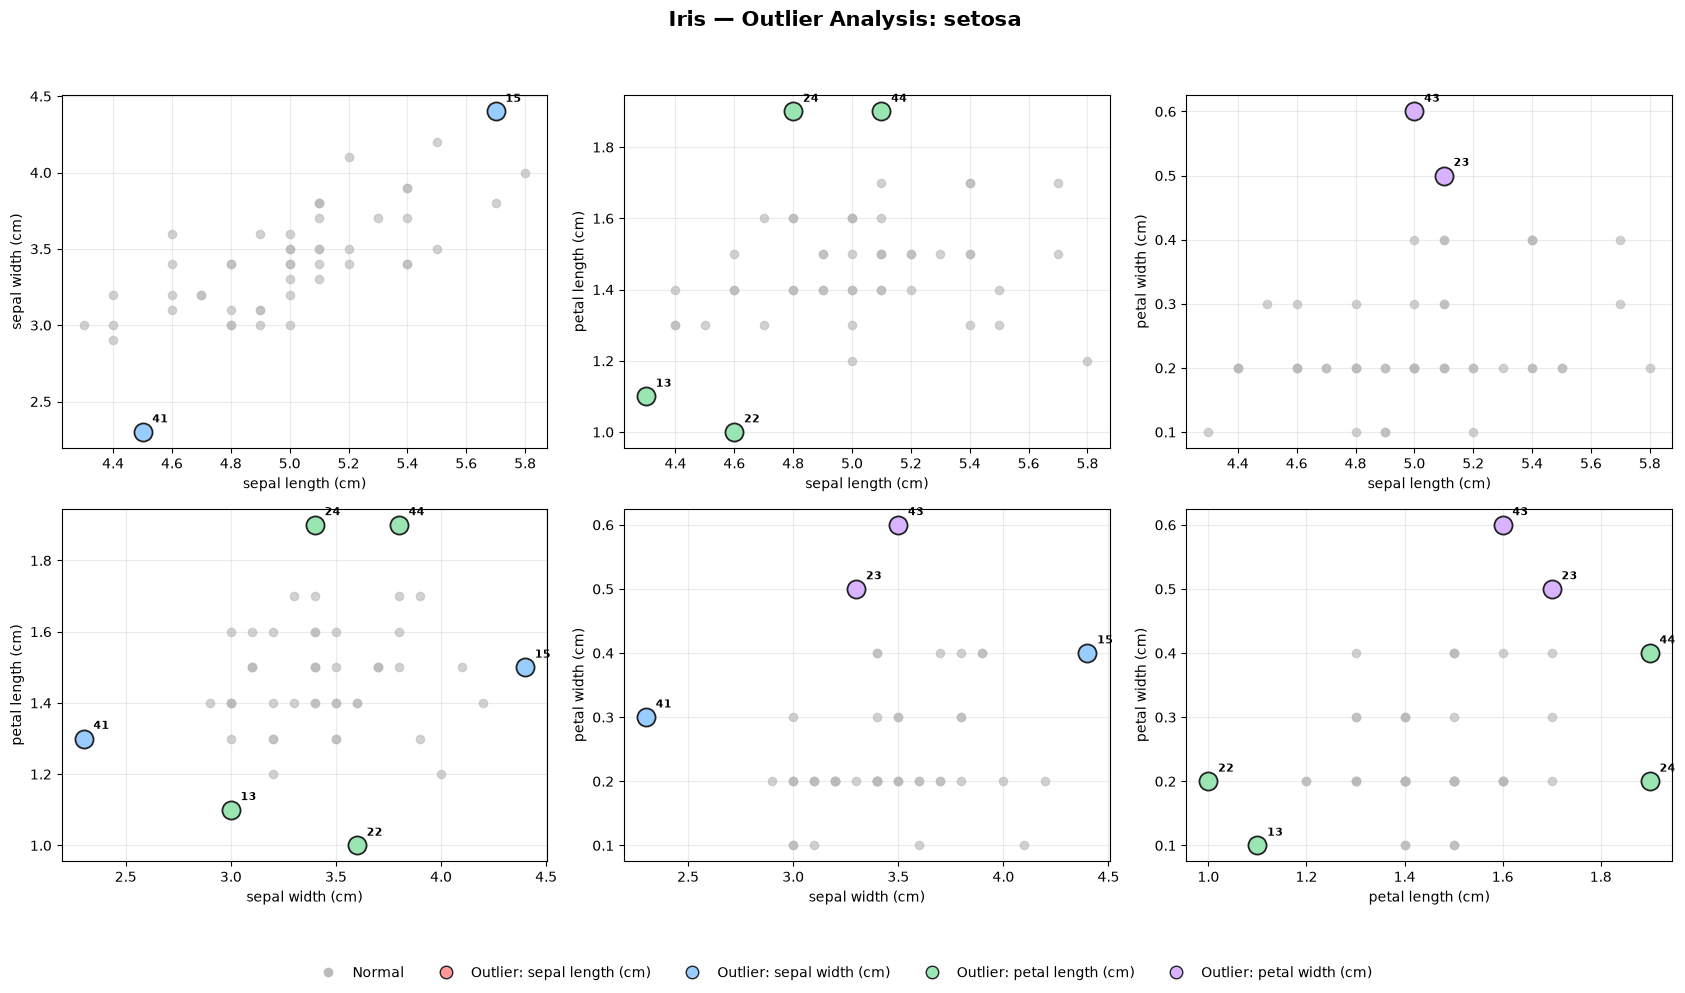

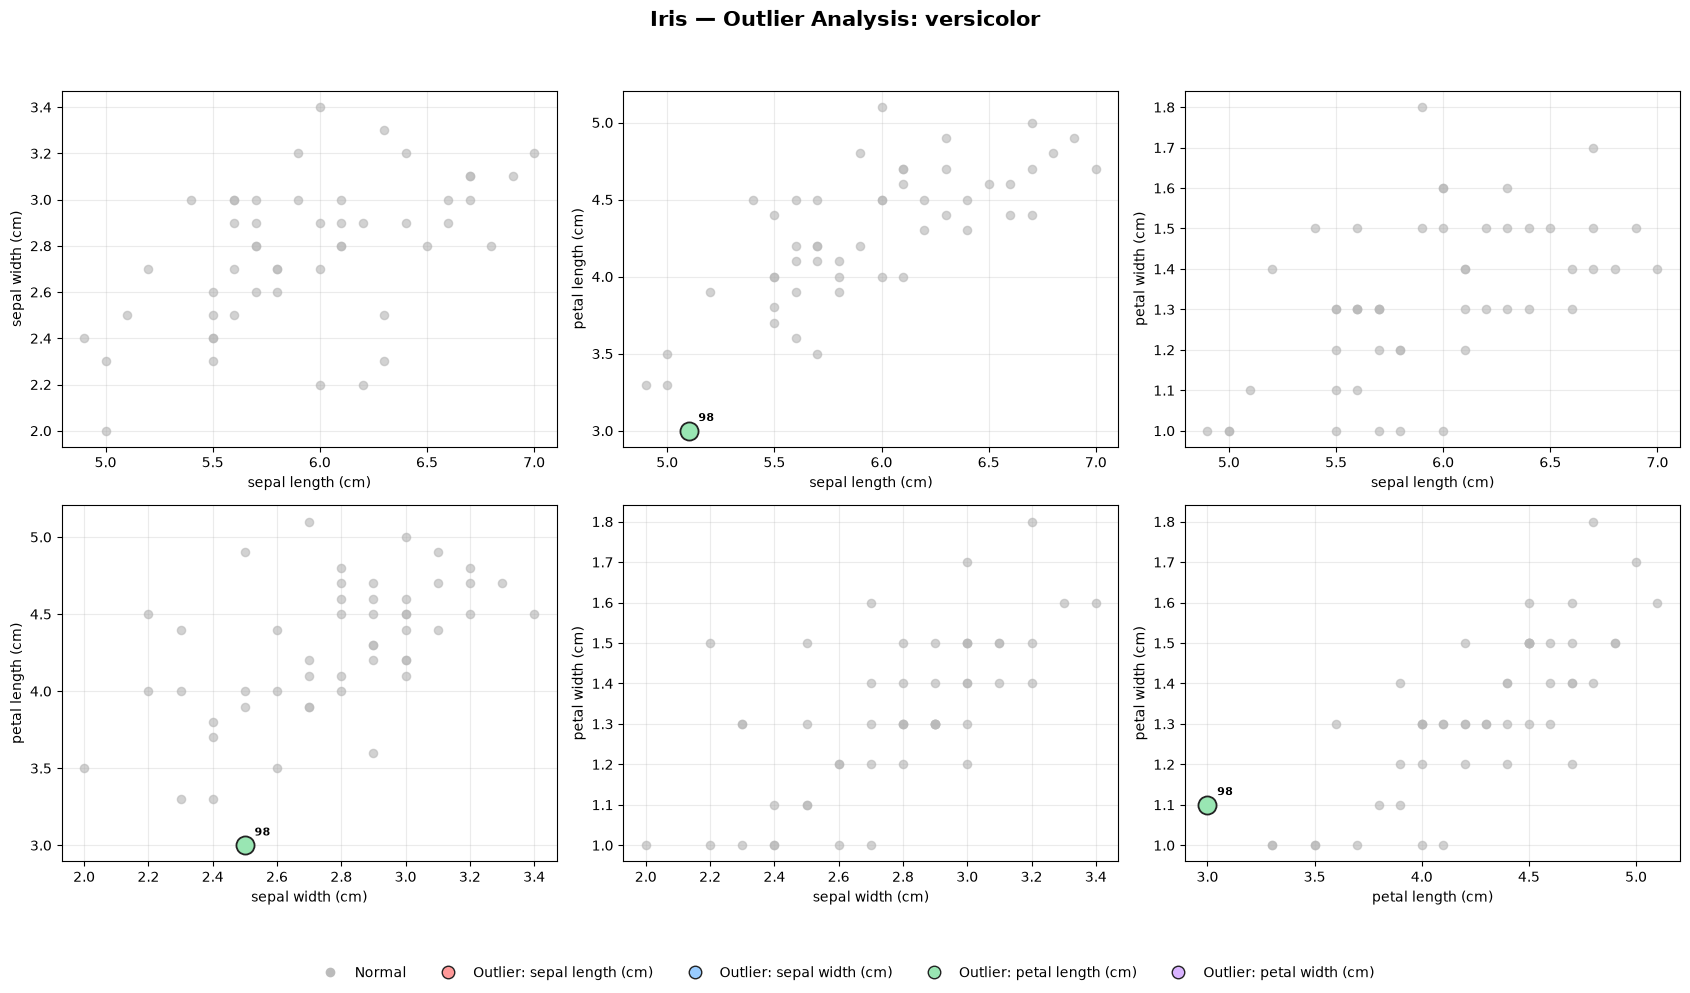

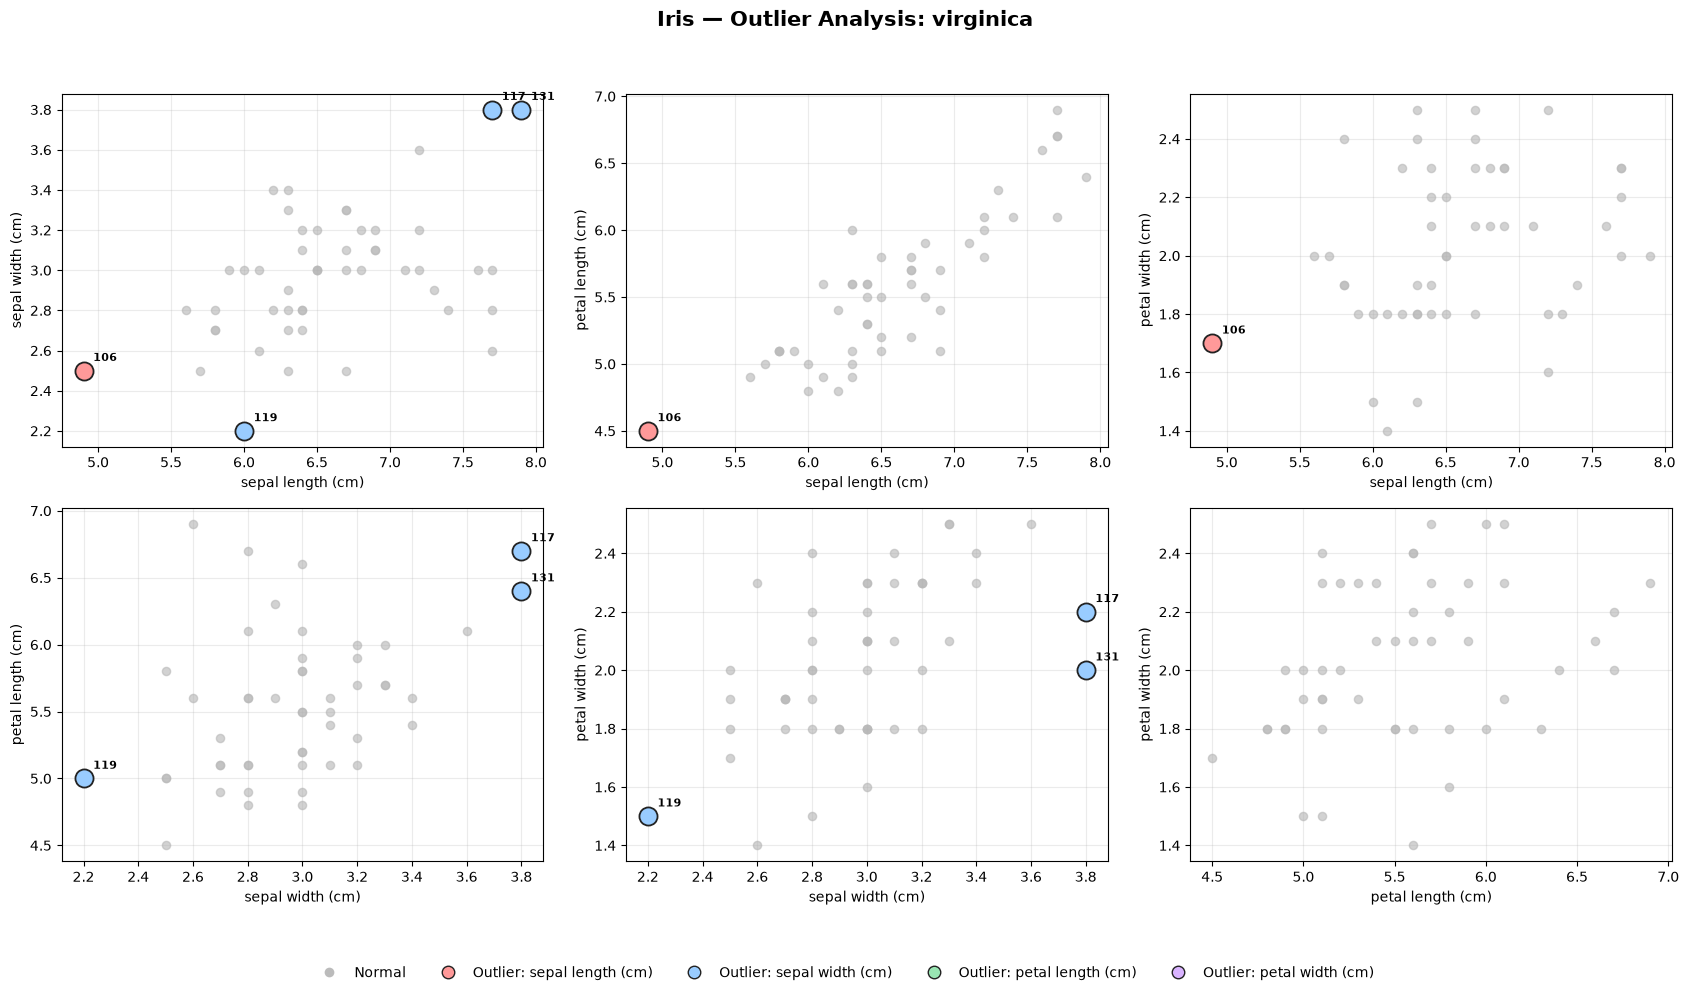

In [9]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from itertools import combinations

# ثبت ویژگی‌هایی که برای هر نمونه پرت تشخیص داده شده‌اند
outlier_features = {}

for idx, feature in outlier_cells:
    outlier_features.setdefault(idx, set()).add(feature)

pairs = list(combinations(features, 2))

# راهنمای رنگ‌ها
legend_items = [
    Line2D(
        [0], [0], marker="o", linestyle="",
        markersize=7, markerfacecolor="#BBBBBB",
        markeredgecolor="none", label="Normal"
    )
]

legend_items += [
    Line2D(
        [0], [0], marker="o", linestyle="",
        markersize=9, markerfacecolor=color,
        markeredgecolor="#222222",
        label=f"Outlier: {feature}"
    )
    for feature, color in colors.items()
]

for species in df["species"].unique():
    group = df[df["species"] == species]

    fig, axes = plt.subplots(2, 3, figsize=(17, 10))

    for ax, (fx, fy) in zip(axes.ravel(), pairs):

        # تمام نمونه‌های گونه با رنگ خاکستری
        ax.scatter(
            group[fx], group[fy],
            color="#BBBBBB", s=35, alpha=0.65, zorder=1
        )

        # نمونه‌های پرت در یکی از دو ویژگی محور
        for idx in group.index:
            feats = outlier_features.get(idx, set())
            relevant = [f for f in (fx, fy) if f in feats]

            if not relevant:
                continue

            x = group.loc[idx, fx]
            y = group.loc[idx, fy]

            # اگر هر دو ویژگی پرت باشند، نقطه را با دو رنگ نیم‌دایره‌ای نشان می‌دهیم
            if fx in feats and fy in feats:
                ax.scatter(
                    x, y, s=190, marker="o",
                    facecolor=colors[fx],
                    edgecolor="#222222", linewidth=1.2,
                    zorder=4
                )
                ax.scatter(
                    x, y, s=190, marker="o",
                    facecolor=colors[fy],
                    edgecolor="none", linewidth=0,
                    zorder=5
                )
                # علامت ضربدر روی نقطه نشان می‌دهد هر دو ویژگی پرت‌اند
                ax.scatter(
                    x, y, s=65, marker="x",
                    color="#222222", linewidth=1.5, zorder=6
                )

            else:
                feature = relevant[0]
                ax.scatter(
                    x, y, s=170, color=colors[feature],
                    edgecolors="#222222", linewidths=1.3,
                    zorder=4
                )

            # شماره نمونه فقط یک بار برای هر نمودار
            ax.annotate(
                str(idx), (x, y),
                textcoords="offset points",
                xytext=(7, 7), fontsize=8,
                fontweight="bold", zorder=7
            )

        ax.set_xlabel(fx)
        ax.set_ylabel(fy)
        ax.grid(alpha=0.25)

    fig.suptitle(
        f"Iris — Outlier Analysis: {species}",
        fontsize=15, fontweight="bold"
    )
    fig.legend(
        handles=legend_items,
        loc="lower center", ncol=5, frameon=False
    )
    plt.tight_layout(rect=[0, 0.07, 1, 0.95])
    plt.show()


In [10]:
# ساخت جدول داده‌های پرت از روی outlier_cells (خروجی سلول‌های قبل)
outliers_df = pd.DataFrame([
    {
        "species": df.loc[idx, "species"],
        "row_number": idx,
        "outlier_feature": feature,
        "outlier_value": df.loc[idx, feature]
    }
    for (idx, feature) in outlier_cells
]).sort_values(["species", "row_number", "outlier_feature"]).reset_index(drop=True)

outliers_df

,species,row_number,outlier_feature,outlier_value
0,setosa,13,petal length (cm),1.1
1,setosa,15,sepal width (cm),4.4
2,setosa,22,petal length (cm),1.0
3,setosa,23,petal width (cm),0.5
4,setosa,24,petal length (cm),1.9
5,setosa,41,sepal width (cm),2.3
6,setosa,43,petal width (cm),0.6
7,setosa,44,petal length (cm),1.9
8,versicolor,98,petal length (cm),3.0
9,virginica,106,sepal length (cm),4.9


In [11]:
outlier_summary = (
    outliers_df.groupby(["species", "row_number"])
    ["outlier_feature"]
    .nunique()
    .reset_index(name="number_of_outlier_features")
)

outlier_summary

,species,row_number,number_of_outlier_features
0,setosa,13,1
1,setosa,15,1
2,setosa,22,1
3,setosa,23,1
4,setosa,24,1
5,setosa,41,1
6,setosa,43,1
7,setosa,44,1
8,versicolor,98,1
9,virginica,106,1


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله اول: شناسایی و تحلیل مقادیر پرت (Outlier Detection)

در این مرحله، ابتدا با استفاده از روش دامنه‌ی بین چارکی (Interquartile Range یا IQR)، مقادیر پرت در هر سه گونه‌ی مجموعه‌داده‌ی Iris و بر اساس چهار ویژگی آن، شامل طول کاسبرگ، عرض کاسبرگ، طول گلبرگ و عرض گلبرگ، شناسایی شدند. برای این منظور، چارک اول (Q1)، چارک سوم (Q3) و مقدار IQR برای هر ویژگی در هر گونه محاسبه شد. سپس با استفاده از کران‌های پایین و بالای تعیین‌شده بر اساس این روش، مقادیر پرت مشخص شدند. همچنین، برای نمایش بهتر توزیع داده‌ها و شناسایی بصری مقادیر پرت، نمودارهای جعبه‌ای (Box Plot) رسم شدند.

در ادامه، جدولی شامل نمونه‌هایی که در حداقل یکی از ویژگی‌ها دارای مقدار پرت بودند، تهیه شد. در این جدول، هر ویژگی با رنگی متفاوت مشخص شد تا محل وقوع مقادیر پرت در هر نمونه به‌سادگی قابل تشخیص باشد. به این ترتیب، امکان مقایسه‌ی ویژگی‌های مختلف و بررسی وضعیت نمونه‌های پرت در گونه‌های گوناگون فراهم شد.

در مرحله‌ی بعد، برای بررسی هم‌زمان ارتباط میان ویژگی‌ها و وضعیت مقادیر پرت، نمودارهای پراکندگی (Scatter Plot) برای ترکیب‌های دوتایی از چهار ویژگی رسم شدند. این نمودارها برای هر سه گونه تهیه شدند و نمونه‌های پرت با رنگ‌های اختصاصی ویژگی مربوطه نمایش داده شدند. هدف از این بخش، بررسی بصری این موضوع بود که آیا یک نمونه در یک ویژگی یا به‌طور هم‌زمان در چند ویژگی دارای مقدار پرت است.

پس از بررسی نتایج جدول و نمودارها، مشخص شد که هر یک از نمونه‌های شناسایی‌شده به‌عنوان پرت، تنها در یکی از چهار ویژگی دارای مقدار پرت است و هیچ نمونه‌ای در بیش از یک ویژگی به‌طور هم‌زمان پرت تشخیص داده نشد.

در نهایت، جدولی شامل نام گونه، شماره‌ی ردیف نمونه، ویژگی دارای مقدار پرت (Outlier Feature) و مقدار آن ویژگی (Outlier Value) تهیه شد. این جدول امکان بررسی دقیق‌تر مقادیر پرت شناسایی‌شده و تعیین ویژگی مربوط به هر مورد را فراهم کرد. در نتیجه، با استفاده از محاسبات آماری و نمایش‌های بصری، مقادیر پرت مجموعه‌داده شناسایی و وضعیت آن‌ها در ویژگی‌های مختلف بررسی شد.

</div>

In [12]:
# ساخت جدول مقایسه داده‌های پرت با آمار گونه
rows = []

for _, r in outliers_df.iterrows():
    species = r["species"]
    feature = r["outlier_feature"]
    value = r["outlier_value"]

    group = df.loc[df["species"] == species, feature]

    mean_value = group.mean()
    median_value = group.median()
    min_value = group.min()
    max_value = group.max()

    modes = group.mode()
    mode_value = modes.iloc[0] if not modes.empty else float("nan")

    rows.append({
        "گونه": species,
        "ویژگی": feature,
        "شماره ردیف": r["row_number"],
        "مقدار پرت": value,
        "میانگین گونه": mean_value,
        "مد گونه": mode_value,
        "میانه گونه": median_value,
        "حداقل گونه": min_value,
        "حداکثر گونه": max_value,
        "فاصله از میانگین": value - mean_value,
        "فاصله از مد": value - mode_value,
        "فاصله از میانه": value - median_value,
        "درصد فاصله از میانگین": (
            (value - mean_value) / mean_value * 100
            if mean_value != 0 else float("nan")
        ),
        "درصد فاصله از مد": (
            (value - mode_value) / mode_value * 100
            if mode_value != 0 else float("nan")
        ),
        "درصد فاصله از میانه": (
            (value - median_value) / median_value * 100
            if median_value != 0 else float("nan")
        )
    })

outlier_comparison = pd.DataFrame(rows)

In [13]:

display(
    outlier_comparison.style
    .format({
        "مقدار پرت": "{:.3f}",
        "میانگین گونه": "{:.3f}",
        "میانه گونه": "{:.3f}",
        "حداقل گونه": "{:.3f}",
        "حداکثر گونه": "{:.3f}",
        "فاصله از میانگین": "{:+.3f}",
        "فاصله از مد": lambda x: x,
        "فاصله از میانه": "{:+.3f}",
        "درصد فاصله از میانگین": "{:+.2f}%",
        "درصد فاصله از مد": lambda x: x,
        "درصد فاصله از میانه": "{:+.2f}%"
    })
    .set_caption("مقایسه داده‌های پرت با آمار هر گونه")
    .set_properties(**{
        "text-align": "center",
        "padding": "8px",
        "border": "1px solid #D9DEE7",
        "white-space": "nowrap"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("color", "#243B53"),
                ("padding", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#263B5A"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#F0F5FA")]
        },
        {
            "selector": "tbody tr:hover",
            "props": [("background-color", "#DCEAF7")]
        }
    ])
    .hide(axis="index")
)


گونه,ویژگی,شماره ردیف,مقدار پرت,میانگین گونه,مد گونه,میانه گونه,حداقل گونه,حداکثر گونه,فاصله از میانگین,فاصله از مد,فاصله از میانه,درصد فاصله از میانگین,درصد فاصله از مد,درصد فاصله از میانه
setosa,petal length (cm),13,1.100,1.462,1.400000,1.500,1.000,1.900,-0.362,-0.2999999999999998,-0.400,-24.76%,-21.428571428571416,-26.67%
setosa,sepal width (cm),15,4.400,3.428,3.400000,3.400,2.300,4.400,+0.972,1.0000000000000004,+1.000,+28.35%,29.411764705882366,+29.41%
setosa,petal length (cm),22,1.000,1.462,1.400000,1.500,1.000,1.900,-0.462,-0.3999999999999999,-0.500,-31.60%,-28.571428571428566,-33.33%
setosa,petal width (cm),23,0.500,0.246,0.200000,0.200,0.100,0.600,+0.254,0.3,+0.300,+103.25%,149.99999999999997,+150.00%
setosa,petal length (cm),24,1.900,1.462,1.400000,1.500,1.000,1.900,+0.438,0.5,+0.400,+29.96%,35.714285714285715,+26.67%
setosa,sepal width (cm),41,2.300,3.428,3.400000,3.400,2.300,4.400,-1.128,-1.1,-1.100,-32.91%,-32.35294117647059,-32.35%
setosa,petal width (cm),43,0.600,0.246,0.200000,0.200,0.100,0.600,+0.354,0.39999999999999997,+0.400,+143.90%,199.99999999999997,+200.00%
setosa,petal length (cm),44,1.900,1.462,1.400000,1.500,1.000,1.900,+0.438,0.5,+0.400,+29.96%,35.714285714285715,+26.67%
versicolor,petal length (cm),98,3.000,4.260,4.500000,4.350,3.000,5.100,-1.260,-1.5,-1.350,-29.58%,-33.33333333333333,-31.03%
virginica,sepal length (cm),106,4.900,6.588,6.300000,6.500,4.900,7.900,-1.688,-1.3999999999999995,-1.600,-25.62%,-22.222222222222214,-24.62%


In [14]:
import pandas as pd

feature = "petal width (cm)"
species = "setosa"
sample_numbers = [23, 43]

# محاسبه چارک‌ها برای گونه Setosa
data = df[df["species"].str.lower() == species]

Q1 = data[feature].quantile(0.25)
Q3 = data[feature].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# انتخاب نمونه‌های 23 و 43
samples = df.loc[sample_numbers, ["species", feature]].copy()

# محاسبه فاصله از مرزها و تشخیص پرت بودن
samples["IQR Lower"] = lower_bound
samples["IQR Upper"] = upper_bound

samples["فاصله از مرز پایین"] = samples[feature] - lower_bound
samples["فاصله از مرز بالا"] = samples[feature] - upper_bound

samples["وضعیت"] = samples[feature].apply(
    lambda x: "پرت پایین" if x < lower_bound
    else "پرت بالا" if x > upper_bound
    else "عادی"
)

display(
    samples.round(3).style
    .set_properties(**{"text-align": "center", "padding": "8px", "border": "1px solid #D5DEE8"})
    .set_table_styles([
        {"selector": "th", "props": [("background-color", "#334E68"), ("color", "white"), ("font-weight", "bold"), ("text-align", "center"), ("padding", "9px"), ("border", "1px solid #D5DEE8")]},
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#F1F6FB")]},
        {"selector": "tbody tr:hover", "props": [("background-color", "#E1EDF8")]}
    ])
)

,species,petal width (cm),IQR Lower,IQR Upper,فاصله از مرز پایین,فاصله از مرز بالا,وضعیت
23,setosa,0.500000,0.050000,0.450000,0.450000,0.050000,پرت بالا
43,setosa,0.600000,0.050000,0.450000,0.550000,0.150000,پرت بالا


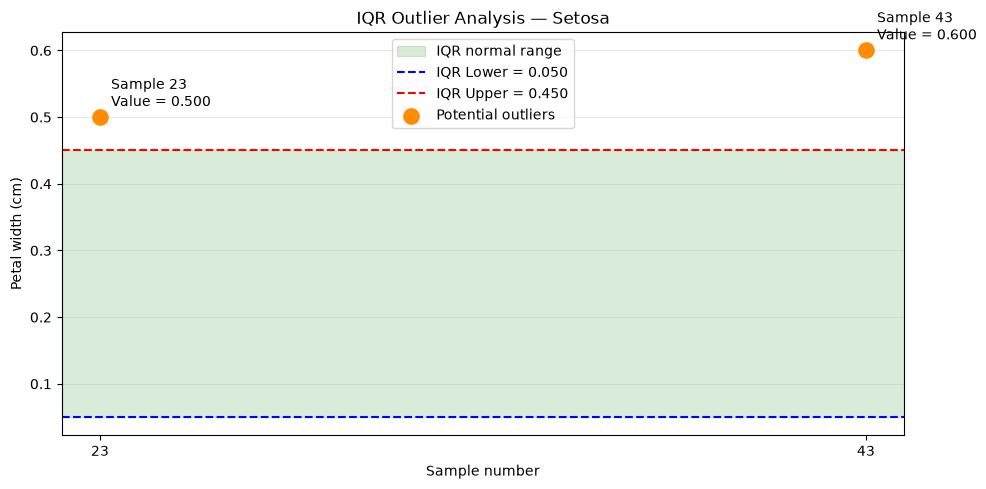

In [15]:
import matplotlib.pyplot as plt

# مقادیر نمونه‌ها از جدول samples که در مرحله قبل ساختیم
values = samples[feature].values
sample_numbers = samples.index

fig, ax = plt.subplots(figsize=(10, 5))

# بازه مجاز IQR
ax.axhspan(
    lower_bound, upper_bound,
    color="green", alpha=0.15,
    label="IQR normal range"
)

# مرزهای IQR
ax.axhline(
    lower_bound, color="blue", linestyle="--",
    label=f"IQR Lower = {lower_bound:.3f}"
)
ax.axhline(
    upper_bound, color="red", linestyle="--",
    label=f"IQR Upper = {upper_bound:.3f}"
)

# نمایش دو نمونه
ax.scatter(
    sample_numbers, values,
    color="darkorange", s=120, zorder=3,
    label="Potential outliers"
)

# نوشتن مقدار کنار هر نقطه
for number, value in zip(sample_numbers, values):
    ax.annotate(
        f"Sample {number}\nValue = {value:.3f}",
        (number, value),
        xytext=(8, 8),
        textcoords="offset points"
    )

ax.set_xlabel("Sample number")
ax.set_ylabel("Petal width (cm)")
ax.set_title("IQR Outlier Analysis — Setosa")
ax.set_xticks(sample_numbers)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:

import pandas as pd

# انتخاب گونه Setosa
setosa = df[df["species"] == "setosa"].copy()

# ویژگی‌های کاسبرگ و گلبرگ
features = iris.feature_names

# محاسبه چارک‌ها و مرزهای IQR برای هر ویژگی در Setosa
Q1 = setosa[features].quantile(0.25)
Q3 = setosa[features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# انتخاب نمونه‌های 23 و 43
selected = setosa.loc[[23, 43]]

# ساخت جدول مقایسه
results = []

for sample_id, row in selected.iterrows():
    for feature in features:
        value = row[feature]
        lower = lower_bound[feature]
        upper = upper_bound[feature]

        if value < lower:
            status = "Outlier - Lower"
            distance = value - lower
        elif value > upper:
            status = "Outlier - Upper"
            distance = value - upper
        else:
            status = "Normal"
            distance = 0

        results.append({
            "Sample": sample_id,
            "Species": row["species"],
            "Feature": feature,
            "Value": value,
            "IQR Lower": lower,
            "IQR Upper": upper,
            "Distance Outside IQR": distance,
            "Status": status
        })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.style
    .format({
        "Value": "{:.3f}",
        "IQR Lower": "{:.3f}",
        "IQR Upper": "{:.3f}",
        "Distance Outside IQR": "{:+.3f}"
    })
    .hide(axis="index")
)


Sample,Species,Feature,Value,IQR Lower,IQR Upper,Distance Outside IQR,Status
23,setosa,sepal length (cm),5.100,4.200,5.800,+0.000,Normal
23,setosa,sepal width (cm),3.300,2.487,4.388,+0.000,Normal
23,setosa,petal length (cm),1.700,1.137,1.838,+0.000,Normal
23,setosa,petal width (cm),0.500,0.050,0.450,+0.050,Outlier - Upper
43,setosa,sepal length (cm),5.000,4.200,5.800,+0.000,Normal
43,setosa,sepal width (cm),3.500,2.487,4.388,+0.000,Normal
43,setosa,petal length (cm),1.600,1.137,1.838,+0.000,Normal
43,setosa,petal width (cm),0.600,0.050,0.450,+0.150,Outlier - Upper


In [17]:

import pandas as pd
import numpy as np
from sklearn.datasets import load_iris

# بارگذاری دیتاست
iris = load_iris(as_frame=True)
df = iris.frame

# تعیین نام گونه‌ها
df["species"] = df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

# انتخاب فقط گونه Setosa
setosa = df[df["species"] == "setosa"].copy()

# شاخص‌های آماری قبل از حذف داده‌های پرت
print("Setosa - Before Removing Outliers")

summary_before = setosa[iris.feature_names].agg(
    ["mean", "median", "var", "std", "min", "max"]
).round(3)

display(summary_before.style
    .set_properties(**{"text-align": "center", "padding": "8px", "border": "1px solid #D5DEE8"})
    .set_table_styles([
        {"selector": "th", "props": [("background-color", "#334E68"), ("color", "white"), ("font-weight", "bold"), ("text-align", "center"), ("padding", "9px"), ("border", "1px solid #D5DEE8")]},
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#F1F6FB")]}
    ])
)

# حذف نمونه‌های 23 و 43
setosa_without_outliers = setosa.drop(index=[23, 43])

# شاخص‌های آماری بعد از حذف داده‌های پرت
print("Setosa - After Removing Outliers")

summary_after = setosa_without_outliers[iris.feature_names].agg(
    ["mean", "median", "var", "std", "min", "max"]
).round(3)

display(summary_after.style
    .set_properties(**{"text-align": "center", "padding": "8px", "border": "1px solid #D5DEE8"})
    .set_table_styles([
        {"selector": "th", "props": [("background-color", "#334E68"), ("color", "white"), ("font-weight", "bold"), ("text-align", "center"), ("padding", "9px"), ("border", "1px solid #D5DEE8")]},
        {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#F1F6FB")]}
    ])
)


Setosa - Before Removing Outliers


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,5.006000,3.428000,1.462000,0.246000
median,5.000000,3.400000,1.500000,0.200000
var,0.124000,0.144000,0.030000,0.011000
std,0.352000,0.379000,0.174000,0.105000
min,4.300000,2.300000,1.000000,0.100000
max,5.800000,4.400000,1.900000,0.600000


Setosa - After Removing Outliers


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,5.004000,3.429000,1.454000,0.233000
median,5.000000,3.400000,1.450000,0.200000
var,0.129000,0.149000,0.030000,0.007000
std,0.360000,0.386000,0.173000,0.086000
min,4.300000,2.300000,1.000000,0.100000
max,5.800000,4.400000,1.900000,0.400000


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله دوم: بررسی دقیق نمونه‌های پرت و ارزیابی تأثیر حذف آن‌ها

در این مرحله، نمونه‌های پرت شناسایی‌شده با استفاده از شاخص‌های آماری هر گونه مورد بررسی دقیق‌تر قرار گرفتند. برای این منظور، فاصله و درصد فاصله‌ی مقادیر پرت از شاخص‌هایی مانند میانگین، میانه و مد محاسبه شد. نتایج این بررسی نشان داد که دو نمونه از گونه‌ی Setosa، با شماره‌ردیف‌های ۲۳ و ۴۳، نسبت به این شاخص‌های آماری فاصله‌ی قابل‌توجهی دارند؛ بنابراین، این دو نمونه برای تحلیل دقیق‌تر انتخاب شدند.

در ادامه، این دو نمونه با استفاده از روش دامنه‌ی بین چارکی (IQR) بررسی شدند. در این روش، کران پایین و کران بالای داده‌ها محاسبه شد تا مشخص شود هر نمونه چه فاصله‌ای از محدوده‌ی قابل‌قبول داده‌ها دارد. همچنین، با استفاده از کتابخانه‌ی Matplotlib، نمودار تحلیل مقادیر پرت بر اساس IQR رسم شد تا موقعیت هر نمونه نسبت به کران‌های پایین و بالای این محدوده به‌صورت بصری مشخص شود.

سپس، هر دو نمونه در تمام چهار ویژگی مجموعه‌داده، شامل طول کاسبرگ، عرض کاسبرگ، طول گلبرگ و عرض گلبرگ، مورد بررسی قرار گرفتند تا مشخص شود آیا در ویژگی‌های دیگر نیز مقدار پرت دارند یا خیر. نتایج نشان داد که هر دو نمونه‌ی شماره‌ی ۲۳ و ۴۳ فقط در ویژگی عرض گلبرگ (Petal Width) به‌عنوان مقدار پرت شناسایی می‌شوند و در سه ویژگی دیگر، مقدار پرت محسوب نمی‌شوند.

در مرحله‌ی بعد، به‌منظور ارزیابی تأثیر حذف این نمونه‌ها بر توزیع داده‌ها، شاخص‌های آماری مجموعه‌داده پیش و پس از حذف مقادیر پرت با یکدیگر مقایسه شدند. شاخص‌های بررسی‌شده شامل حداقل مقدار، میانه، واریانس، انحراف معیار و حداکثر مقدار بودند. نتایج نشان داد که پس از حذف نمونه‌های پرت، حداقل مقدار حدود ۰٫۰۱۳، واریانس حدود ۰٫۰۰۴، انحراف معیار حدود ۰٫۰۱۴ و حداکثر مقدار حدود ۰٫۲ کاهش پیدا کردند.

با توجه به نتایج به‌دست‌آمده، تغییرات ایجادشده در شاخص‌های آماری بررسی‌شده نسبتاً محدود بود. بنابراین، از آنجا که حذف این دو نمونه تغییر چشمگیری در این شاخص‌ها ایجاد نکرد، تصمیم گرفته شد که صرفاً بر اساس پرت بودن آماری، این نمونه‌ها به‌صورت خودکار از مجموعه‌داده حذف نشوند. این تصمیم بر اهمیت بررسی ویژگی‌های داده‌ها و ارزیابی تأثیر مقادیر پرت پیش از حذف آن‌ها تأکید دارد.

</div>

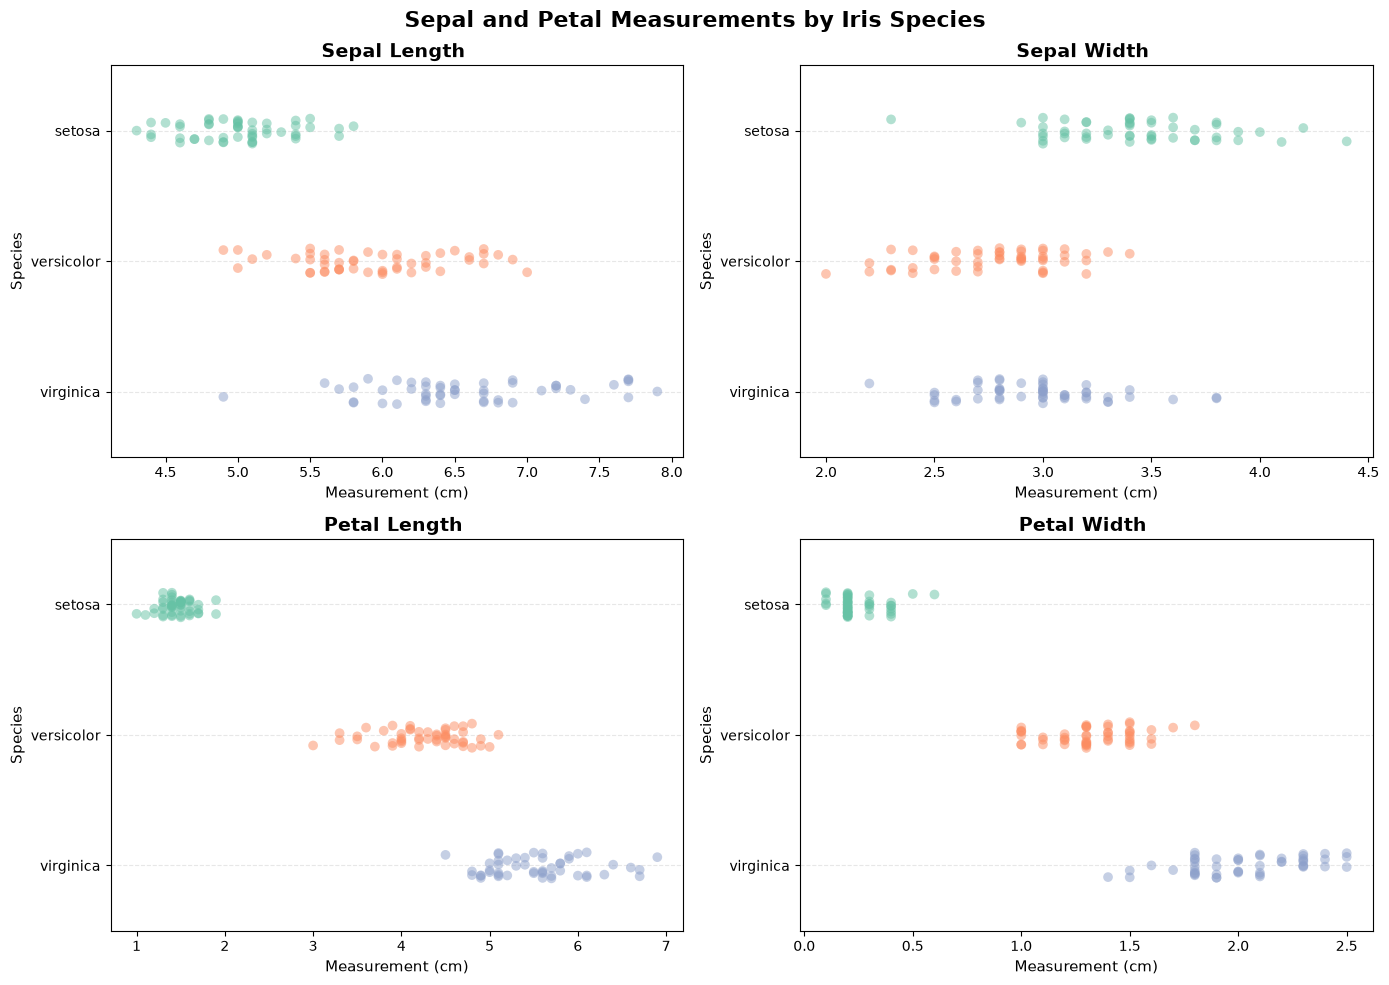

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'sepal length (cm)',
    'sepal width (cm)',
    'petal length (cm)',
    'petal width (cm)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

species_colors = ['#66c2a5', '#fc8d62', '#8da0cb']

for ax, feature in zip(axes, features):
    sns.stripplot(
        data=df,
        y='species',
        x=feature,
        hue='species',
        palette=species_colors,
        jitter=True,
        dodge=False,
        alpha=0.5,
        size=7,
        legend=False,
        ax=ax
    )

    ax.set_title(
        feature.replace('(cm)', '').title(),
        fontsize=14,
        fontweight='bold'
    )
    ax.set_xlabel('Measurement (cm)', fontsize=11)
    ax.set_ylabel('Species', fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.suptitle(
    'Sepal and Petal Measurements by Iris Species',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

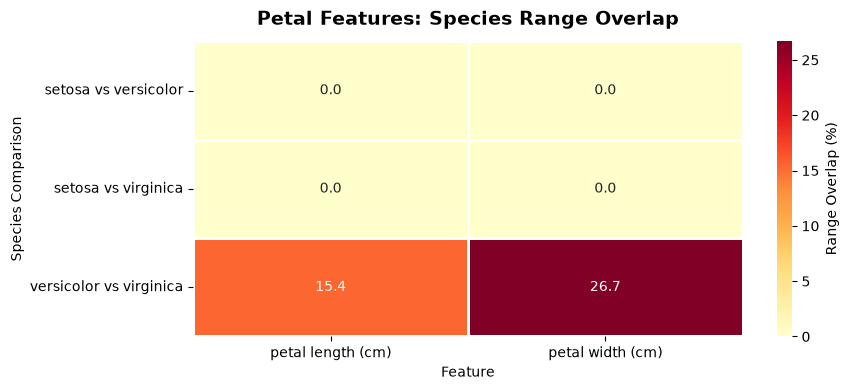

In [19]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

features = ['petal length (cm)', 'petal width (cm)']
species_list = df['species'].unique()

results = []

for sp1, sp2 in combinations(species_list, 2):
    row = {'Species Pair': f'{sp1} vs {sp2}'}

    for feature in features:
        d1 = df[df['species'] == sp1][feature]
        d2 = df[df['species'] == sp2][feature]

        overlap_start = max(d1.min(), d2.min())
        overlap_end = min(d1.max(), d2.max())

        overlap = max(0, overlap_end - overlap_start)

        combined_range = max(d1.max(), d2.max()) - min(
            d1.min(), d2.min()
        )

        row[feature] = (
            overlap / combined_range * 100
            if combined_range > 0 else 0
        )

    results.append(row)

overlap_df = pd.DataFrame(results).set_index('Species Pair')

plt.figure(figsize=(9, 4))

sns.heatmap(
    overlap_df,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=2,
    linecolor='white',
    vmin=0,
    cbar_kws={'label': 'Range Overlap (%)'}
)

plt.title('Petal Features: Species Range Overlap',
          fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Feature')
plt.ylabel('Species Comparison')
plt.tight_layout()
plt.show()


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله سوم: بررسی میزان هم‌پوشانی بین گونه‌های مختلف

در این مرحله، با استفاده از نمودارهای پراکندگی (Scatter Plot)، توزیع مقادیر هر چهار ویژگی در سه گونه‌ی مجموعه‌داده‌ی Iris بررسی شد. هدف از این کار، مقایسه‌ی توزیع ویژگی‌ها بین گونه‌های مختلف و بررسی میزان هم‌پوشانی آن‌ها در هر ویژگی بود. این نمودارها امکان شناسایی ویژگی‌هایی را فراهم کردند که در آن‌ها نمونه‌های گونه‌های مختلف مقادیر مشابهی دارند و در نتیجه، تفکیک آن‌ها از یکدیگر دشوارتر است.

در ادامه، یک نمودار حرارتی (Heatmap) برای نمایش میزان هم‌پوشانی بین گونه‌ها در ویژگی‌های مختلف رسم شد. این نمودار به مقایسه‌ی میزان هم‌پوشانی و شناسایی ویژگی‌هایی که در آن‌ها گونه‌های مختلف شباهت بیشتری دارند، کمک کرد.

نتایج نشان داد که دو گونه‌ی Versicolor و Virginica در ویژگی‌های مربوط به گلبرگ، یعنی عرض گلبرگ (Petal Width) و طول گلبرگ (Petal Length)، هم‌پوشانی قابل‌توجهی دارند. میزان هم‌پوشانی گزارش‌شده برای عرض گلبرگ برابر با ۲۶٫۷ درصد و برای طول گلبرگ برابر با ۱۵٫۴ درصد بود. بر این اساس، می‌توان نتیجه گرفت که این دو گونه در ویژگی‌های گلبرگ تا حدی با یکدیگر هم‌پوشانی دارند و تفکیک آن‌ها صرفاً بر اساس این ویژگی‌ها ممکن است دشوارتر باشد.

</div>

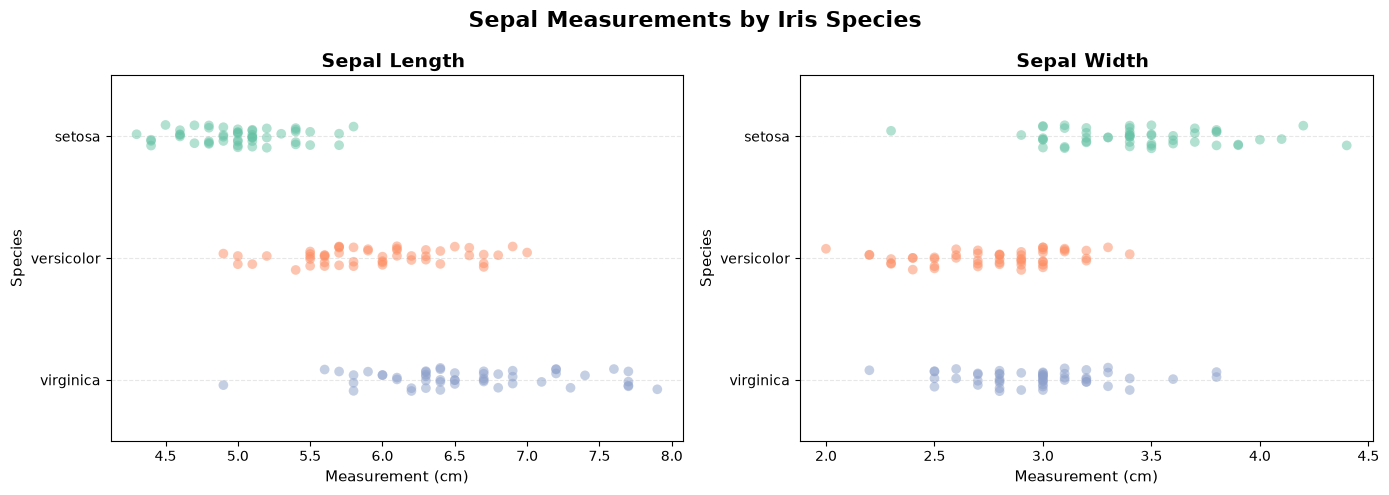

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'sepal length (cm)',
    'sepal width (cm)'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes = axes.flatten()

species_colors = ['#66c2a5', '#fc8d62', '#8da0cb']

for ax, feature in zip(axes, features):
    sns.stripplot(
        data=df,
        y='species',
        x=feature,
        hue='species',
        palette=species_colors,
        jitter=True,
        dodge=False,
        alpha=0.5,
        size=7,
        legend=False,
        ax=ax
    )

    ax.set_title(
        feature.replace('(cm)', '').title(),
        fontsize=14,
        fontweight='bold'
    )
    ax.set_xlabel('Measurement (cm)', fontsize=11)
    ax.set_ylabel('Species', fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.suptitle(
    'Sepal Measurements by Iris Species',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


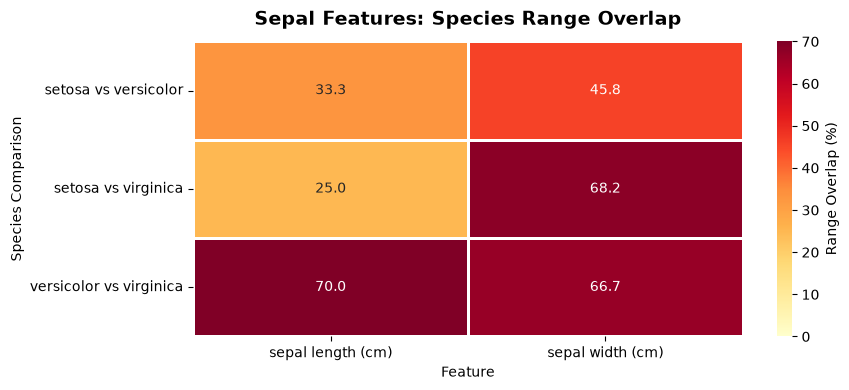

In [21]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

features = ['sepal length (cm)', 'sepal width (cm)']
species_list = df['species'].unique()

results = []

for sp1, sp2 in combinations(species_list, 2):
    row = {'Species Pair': f'{sp1} vs {sp2}'}

    for feature in features:
        d1 = df[df['species'] == sp1][feature]
        d2 = df[df['species'] == sp2][feature]

        overlap_start = max(d1.min(), d2.min())
        overlap_end = min(d1.max(), d2.max())

        overlap = max(0, overlap_end - overlap_start)

        combined_range = max(d1.max(), d2.max()) - min(
            d1.min(), d2.min()
        )

        row[feature] = (
            overlap / combined_range * 100
            if combined_range > 0 else 0
        )

    results.append(row)

overlap_df = pd.DataFrame(results).set_index('Species Pair')

plt.figure(figsize=(9, 4))

sns.heatmap(
    overlap_df,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=2,
    linecolor='white',
    vmin=0,
    cbar_kws={'label': 'Range Overlap (%)'}
)

plt.title('Sepal Features: Species Range Overlap',
          fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Feature')
plt.ylabel('Species Comparison')
plt.tight_layout()
plt.show()


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله چهارم: بررسی میزان هم‌پوشانی گونه‌ها بر اساس ویژگی‌های کاسبرگ

در این مرحله، با استفاده از نمودارهای پراکندگی (Scatter Plot)، توزیع دو ویژگی طول کاسبرگ (Sepal Length) و عرض کاسبرگ (Sepal Width) در سه گونه‌ی مجموعه‌داده‌ی Iris بررسی شد. هدف از این بررسی، مقایسه‌ی توزیع مقادیر ویژگی‌ها و ارزیابی میزان هم‌پوشانی بین گونه‌های مختلف بود.

در ادامه، نمودار حرارتی (Heatmap) برای نمایش درصد هم‌پوشانی محدوده‌ی مقادیر هر ویژگی بین گونه‌ها رسم شد. بر اساس نتایج این نمودار، بیشترین هم‌پوشانی در ویژگی طول کاسبرگ، بین دو گونه‌ی Versicolor و Virginica، با مقدار ۷۰ درصد مشاهده شد. همچنین، میزان هم‌پوشانی این دو گونه در ویژگی عرض کاسبرگ برابر با ۶۶٫۷ درصد بود.

در مقایسه‌ی سایر گونه‌ها نیز مشخص شد که میزان هم‌پوشانی در عرض کاسبرگ می‌تواند قابل‌توجه باشد؛ برای مثال، هم‌پوشانی این ویژگی بین گونه‌های Setosa و Virginica برابر با ۶۸٫۲ درصد و بین Setosa و Versicolor برابر با ۴۵٫۸ درصد بود. در ویژگی طول کاسبرگ نیز مقادیر هم‌پوشانی برای این دو مقایسه به‌ترتیب ۲۵ و ۳۳٫۳ درصد به دست آمد.

در مجموع، نتایج نشان می‌دهد که ویژگی‌های کاسبرگ، به‌ویژه در تفکیک دو گونه‌ی Versicolor و Virginica، محدودیت دارند؛ زیرا این دو گونه در هر دو ویژگی طول و عرض کاسبرگ هم‌پوشانی زیادی نشان می‌دهند. بنابراین، ویژگی‌های کاسبرگ به‌تنهایی برای تفکیک دقیق این دو گونه چندان مناسب نیستند و بهتر است در کنار ویژگی‌های گلبرگ بررسی شوند.

</div>

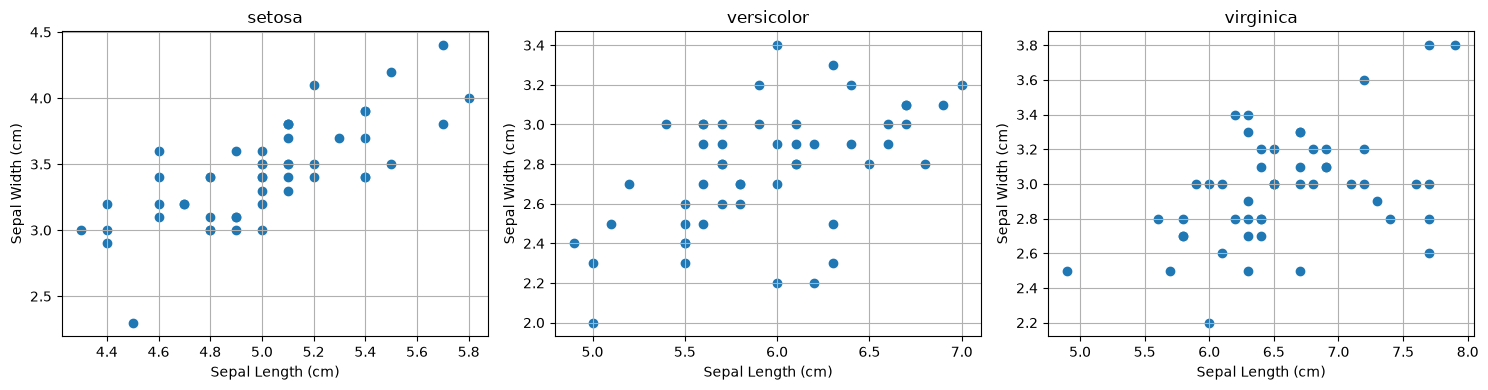

In [22]:

import matplotlib.pyplot as plt

species_list = df['species'].unique()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, species in zip(axes, species_list):
    species_data = df[df['species'] == species]

    ax.scatter(
        species_data['sepal length (cm)'],
        species_data['sepal width (cm)']
    )

    ax.set_title(species)
    ax.set_xlabel('Sepal Length (cm)')
    ax.set_ylabel('Sepal Width (cm)')
    ax.grid(True)

plt.tight_layout()
plt.show()


In [23]:

for species in species_list:
    species_data = df[df['species'] == species]

    correlation = species_data['sepal length (cm)'].corr(
        species_data['sepal width (cm)']
    )

    print(species, ":", round(correlation, 3))


setosa : 0.743
versicolor : 0.526
virginica : 0.457


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


### بررسی تعداد نمونه‌ها در خوشه‌ها

مرحله پنجم: بررسی همبستگی ویژگی‌های کاسبرگ در گونه‌های مختلف

در این مرحله، به‌منظور بررسی رابطه‌ی بین طول کاسبرگ (Sepal Length) و عرض کاسبرگ (Sepal Width)، ابتدا نمودار پراکندگی (Scatter Plot) این دو ویژگی برای هر یک از سه گونه‌ی مجموعه‌داده‌ی Iris رسم شد. سپس، برای ارزیابی عددی شدت و جهت رابطه‌ی خطی بین این دو ویژگی، ضریب همبستگی محاسبه شد.

نتایج به‌دست‌آمده به شرح زیر است:

- Setosa: ضریب همبستگی برابر با ۰٫۷۴۳ است که نشان‌دهنده‌ی همبستگی خطی مثبت نسبتاً قوی بین طول و عرض کاسبرگ در این گونه است.
- Versicolor: ضریب همبستگی برابر با ۰٫۵۶ است که بیانگر وجود همبستگی خطی مثبت متوسط بین دو ویژگی است.
- Virginica: ضریب همبستگی برابر با ۰٫۴۵۷ است که نشان‌دهنده‌ی همبستگی خطی مثبت، اما ضعیف‌تر از دو گونه‌ی دیگر است.

در مجموع، هر سه گونه بین طول و عرض کاسبرگ همبستگی مثبت دارند؛ بااین‌حال، شدت این رابطه در آن‌ها متفاوت است. این همبستگی در گونه‌ی Setosa بیشتر و در گونه‌ی Virginica کمتر است. بنابراین، در گونه‌ی Setosa، افزایش طول کاسبرگ با افزایش عرض آن رابطه‌ی خطی مشخص‌تری دارد؛ درحالی‌که این رابطه در گونه‌ی Virginica ضعیف‌تر است.

</div>

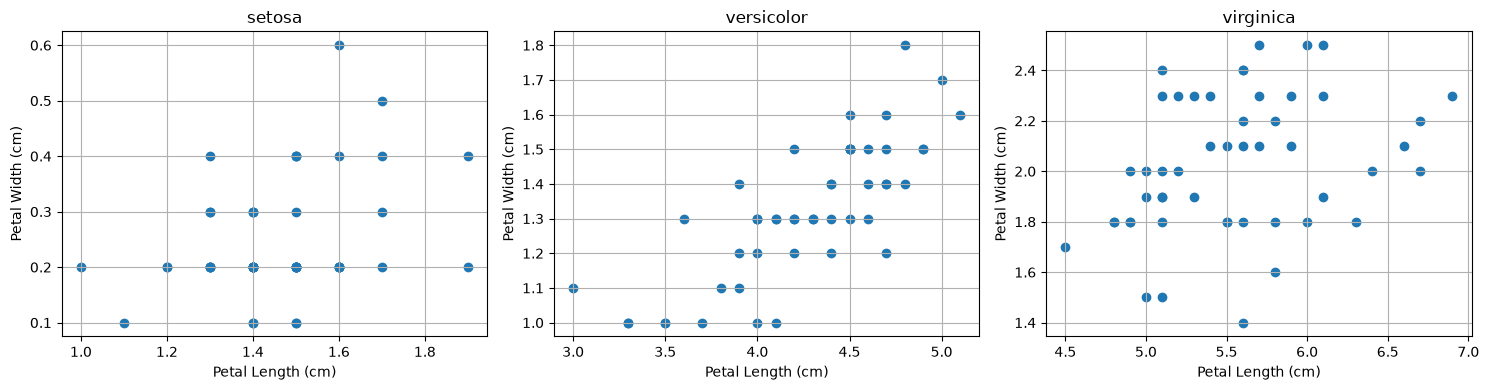

In [24]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, species in zip(axes, species_list):
    species_data = df[df['species'] == species]

    ax.scatter(
        species_data['petal length (cm)'],
        species_data['petal width (cm)']
    )

    ax.set_title(species)
    ax.set_xlabel('Petal Length (cm)')
    ax.set_ylabel('Petal Width (cm)')
    ax.grid(True)

plt.tight_layout()
plt.show()


In [25]:

for species in species_list:
    species_data = df[df['species'] == species]

    correlation = species_data['petal length (cm)'].corr(
        species_data['petal width (cm)']
    )

    print(species, ":", round(correlation, 3))


setosa : 0.332
versicolor : 0.787
virginica : 0.322


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله ششم: بررسی همبستگی ویژگی‌های گلبرگ در گونه‌های مختلف

در این مرحله، رابطه‌ی بین طول گلبرگ (Petal Length) و عرض گلبرگ (Petal Width) در هر یک از سه گونه‌ی مجموعه‌داده‌ی Iris بررسی شد. ابتدا نمودارهای پراکندگی (Scatter Plot) برای مشاهده‌ی الگوی توزیع داده‌ها رسم شدند و سپس ضریب همبستگی بین دو ویژگی برای هر گونه به‌صورت عددی محاسبه شد.

نتایج به‌دست‌آمده به شرح زیر است:

- Setosa: ضریب همبستگی برابر با ۰٫۳۳۲ است که نشان‌دهنده‌ی همبستگی خطی مثبت ضعیف بین طول و عرض گلبرگ است.
- Versicolor: ضریب همبستگی برابر با ۰٫۷۷ است که بیانگر همبستگی خطی مثبت نسبتاً قوی بین دو ویژگی است.
- Virginica: ضریب همبستگی برابر با ۰٫۲۲ است که نشان‌دهنده‌ی همبستگی خطی مثبت ضعیف بین طول و عرض گلبرگ است.

بر اساس نتایج، بیشترین همبستگی بین طول و عرض گلبرگ در گونه‌ی Versicolor مشاهده می‌شود. بنابراین، در این گونه، افزایش طول گلبرگ معمولاً با افزایش عرض آن همراه است. در مقابل، در دو گونه‌ی Setosa و Virginica، رابطه‌ی خطی بین این دو ویژگی ضعیف‌تر است و افزایش طول گلبرگ، ارتباط خطی مشخصی با افزایش عرض آن نشان نمی‌دهد.

در مجموع، مقایسه‌ی ضرایب همبستگی نشان می‌دهد که رابطه‌ی بین ویژگی‌های گلبرگ در گونه‌های مختلف یکسان نیست و گونه‌ی Versicolor نسبت به دو گونه‌ی دیگر، همبستگی خطی قوی‌تری بین طول و عرض گلبرگ دارد.
</div>

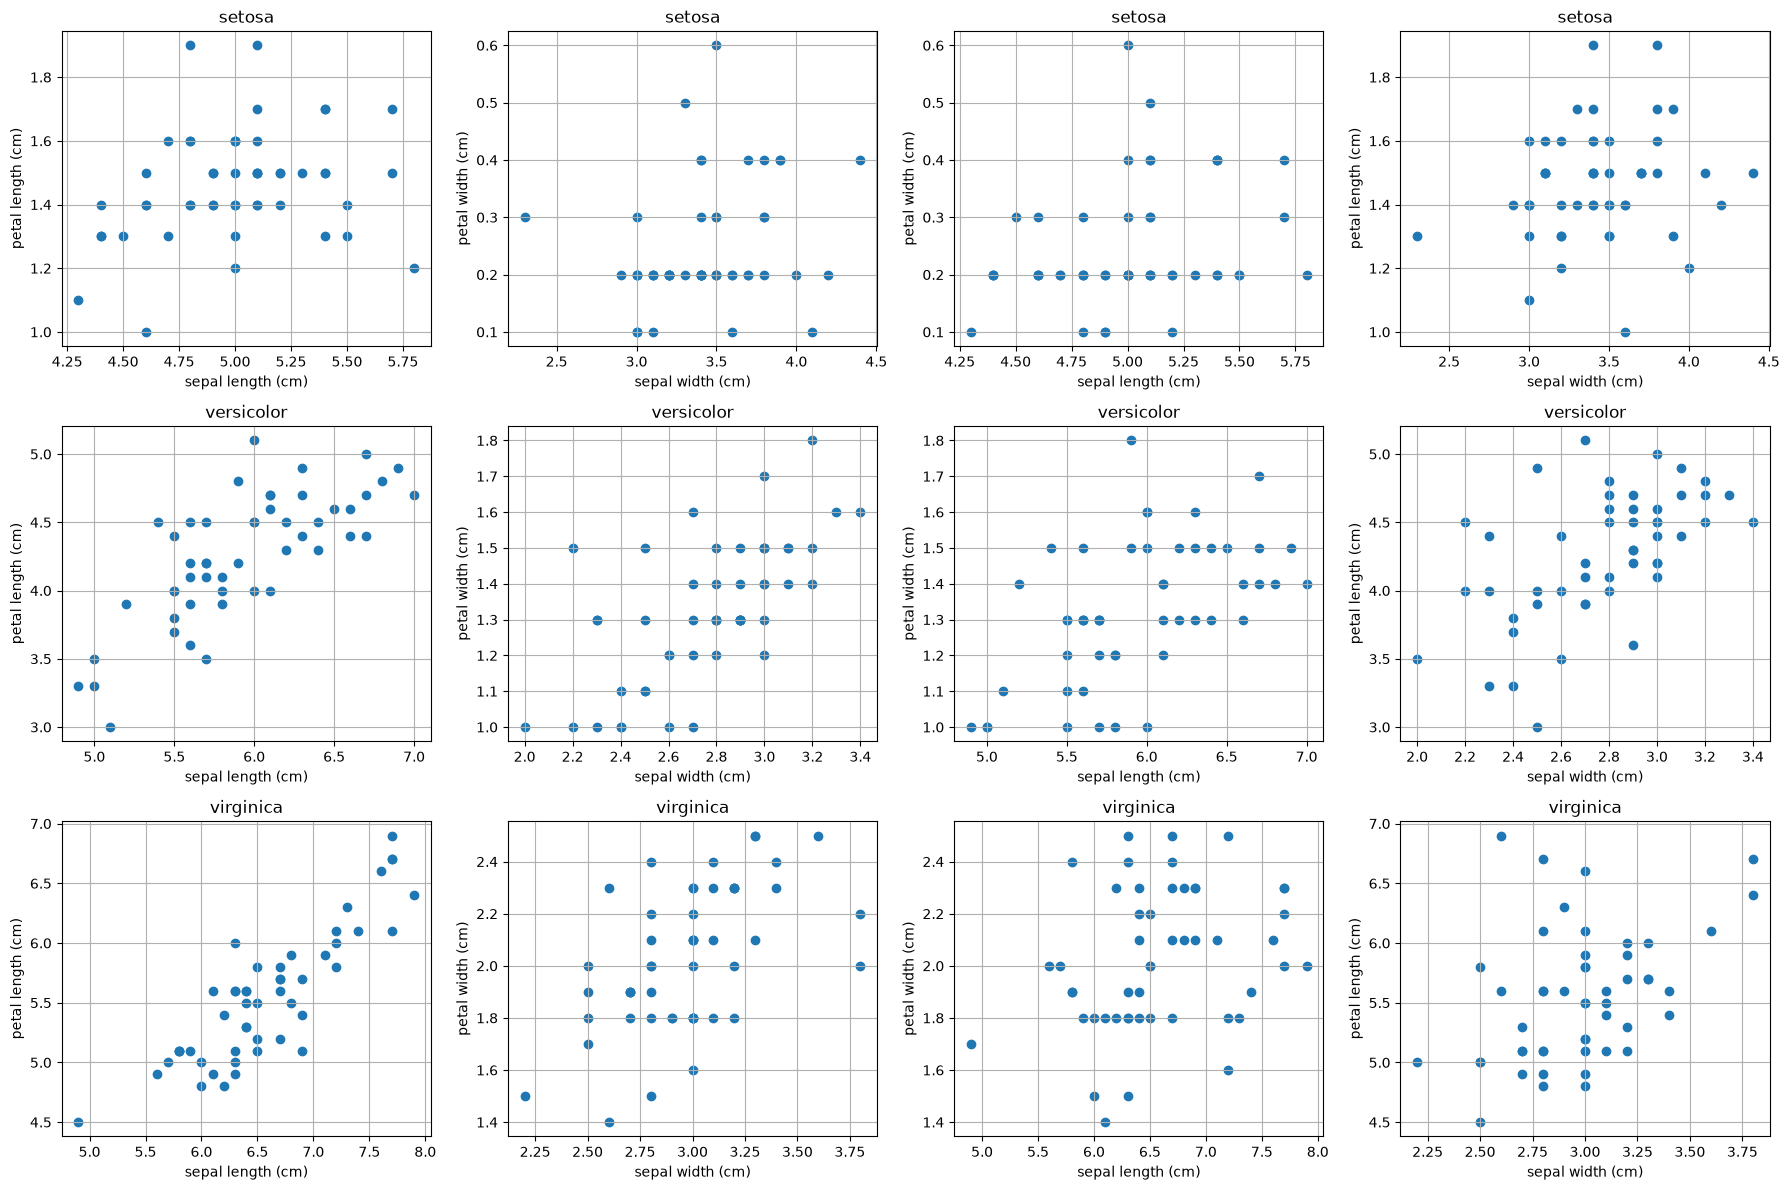

In [26]:

import matplotlib.pyplot as plt

species_list = df['species'].unique()

relationships = [
    ('sepal length (cm)', 'petal length (cm)'),
    ('sepal width (cm)', 'petal width (cm)'),
    ('sepal length (cm)', 'petal width (cm)'),
    ('sepal width (cm)', 'petal length (cm)')
]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for i, species in enumerate(species_list):
    species_data = df[df['species'] == species]

    for j, (x_col, y_col) in enumerate(relationships):
        axes[i, j].scatter(
            species_data[x_col],
            species_data[y_col]
        )

        axes[i, j].set_title(species)
        axes[i, j].set_xlabel(x_col)
        axes[i, j].set_ylabel(y_col)
        axes[i, j].grid(True)

plt.tight_layout()
plt.show()


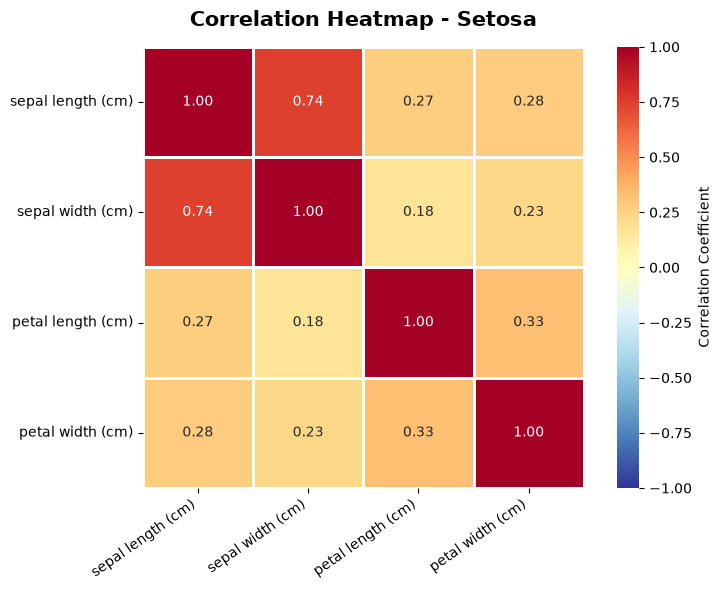

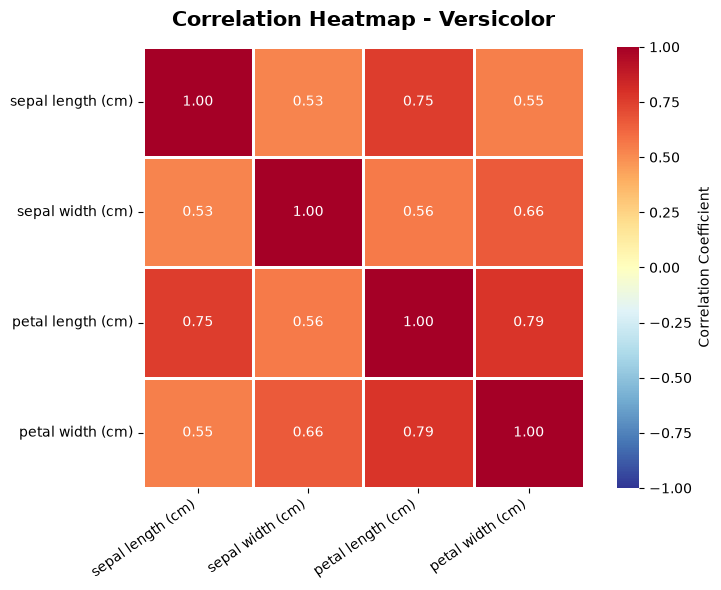

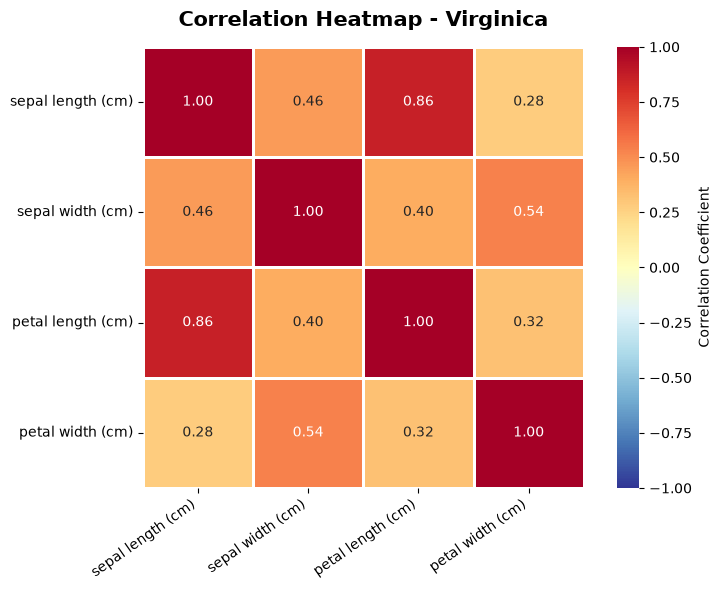

In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'sepal length (cm)',
    'sepal width (cm)',
    'petal length (cm)',
    'petal width (cm)'
]

for species in species_list:
    species_data = df[df['species'] == species]

    corr_matrix = species_data[features].corr()

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt='.2f',
        cmap='RdYlBu_r',
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=2,
        linecolor='white',
        cbar_kws={'label': 'Correlation Coefficient'}
    )

    plt.title(
        f'Correlation Heatmap - {species.title()}',
        fontsize=15,
        fontweight='bold',
        pad=15
    )

    plt.xticks(rotation=35, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله هفتم: بررسی روابط بین ویژگی‌ها در هر گونه با استفاده از نمودارهای پراکندگی و ماتریس همبستگی

در این مرحله، به‌منظور بررسی دقیق‌تر روابط بین ویژگی‌های مجموعه‌داده‌ی Iris، برای هر یک از سه گونه‌ی Setosa، Versicolor و Virginica، نمودارهای پراکندگی (Scatter Plot) مربوط به ترکیب‌های مختلف ویژگی‌ها رسم شد. در مجموع، ۱۲ نمودار برای بررسی روابط بین ویژگی‌های طول و عرض کاسبرگ و طول و عرض گلبرگ تهیه شد. سپس، با استفاده از ماتریس همبستگی (Correlation Matrix) و نمودار حرارتی (Heatmap)، شدت رابطه‌ی خطی بین ویژگی‌ها به‌صورت عددی و بصری بررسی شد.

۱. گونه‌ی Setosa

بر اساس ماتریس همبستگی، ضریب همبستگی بین طول کاسبرگ (Sepal Length) و عرض کاسبرگ (Sepal Width) برابر با ۰٫۷۴ به دست آمد. این مقدار نشان‌دهنده‌ی همبستگی خطی مثبت نسبتاً قوی بین این دو ویژگی است؛ به این معنا که افزایش طول کاسبرگ در این گونه، معمولاً با افزایش عرض آن همراه است.

۲. گونه‌ی Versicolor

در این گونه، ضریب همبستگی بین طول گلبرگ (Petal Length) و طول کاسبرگ (Sepal Length) برابر با ۰٫۷۵ بود که نشان‌دهنده‌ی همبستگی خطی مثبت نسبتاً قوی بین این دو ویژگی است.

همچنین، ضریب همبستگی بین طول گلبرگ و عرض گلبرگ (Petal Width) برابر با ۰٫۷۹ به دست آمد که بیانگر رابطه‌ی خطی مثبت قوی بین این دو ویژگی است. علاوه بر این، همبستگی بین عرض کاسبرگ (Sepal Width) و عرض گلبرگ برابر با ۰٫۶۶ بود که نشان‌دهنده‌ی وجود رابطه‌ی خطی مثبت متوسط تا نسبتاً قوی بین آن‌هاست.

۳. گونه‌ی Virginica

در گونه‌ی Virginica، ضریب همبستگی بین طول گلبرگ و طول کاسبرگ برابر با ۰٫۸۶ به دست آمد. این مقدار نشان‌دهنده‌ی همبستگی خطی مثبت قوی بین این دو ویژگی است.

همچنین، ضریب همبستگی بین عرض کاسبرگ و عرض گلبرگ برابر با ۰٫۵۴ بود که نشان‌دهنده‌ی همبستگی خطی مثبت متوسط بین این دو ویژگی است.

جمع‌بندی

نتایج ماتریس‌های همبستگی نشان می‌دهند که شدت رابطه‌ی خطی بین ویژگی‌ها در گونه‌های مختلف متفاوت است. در گونه‌ی Setosa، طول و عرض کاسبرگ همبستگی مثبت نسبتاً قوی دارند. در گونه‌ی Versicolor، همبستگی بین طول گلبرگ و عرض گلبرگ و نیز بین طول گلبرگ و طول کاسبرگ قابل‌توجه است. در گونه‌ی Virginica نیز بیشترین همبستگی در میان روابط ذکرشده، مربوط به طول گلبرگ و طول کاسبرگ با ضریب ۰٫۸۶ است.

این بررسی به شناسایی ویژگی‌هایی کمک می‌کند که در هر گونه رابطه‌ی خطی قوی‌تری با یکدیگر دارند. البته، همبستگی بالا به‌تنهایی به معنای رابطه‌ی علت و معلولی نیست و لزوماً نشان نمی‌دهد که آن ویژگی‌ها برای تفکیک گونه‌ها از یکدیگر مناسب‌تر هستند.
</div>

In [28]:
from sklearn.preprocessing import StandardScaler

# استانداردسازی ۴ ویژگی اصلی
X = df[iris.feature_names]
X_scaled = StandardScaler().fit_transform(X)

In [29]:
import pandas as pd

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df.index
)

print(X_scaled_df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


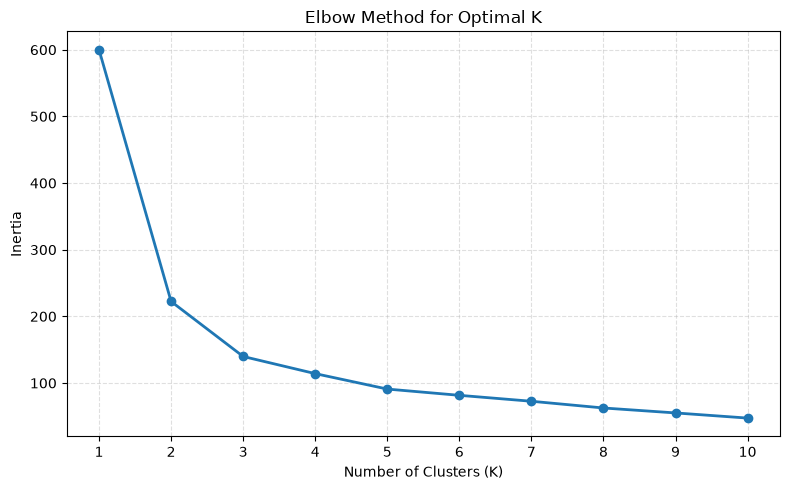

In [30]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker='o',
    linewidth=2
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [31]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

In [32]:
import pandas as pd

print(pd.Series(clusters).value_counts().sort_index())

0    53
1    50
2    47
Name: count, dtype: int64


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله هشتم: اجرای الگوریتم K-Means برای خوشه‌بندی داده‌ها

پس از مقیاس‌بندی چهار ویژگی طول کاسبرگ، عرض کاسبرگ، طول گلبرگ و عرض گلبرگ، الگوریتم K-Means برای خوشه‌بندی نمونه‌های مجموعه‌داده‌ی Iris اجرا شد. با توجه به بررسی نمودار آرنج و انتخاب تعداد خوشه‌ها، مقدار "n_clusters" برابر با ۳ تنظیم شد.

همچنین، برای اطمینان از تکرارپذیری نتایج، مقدار "random_state" برابر با ۴۲ قرار داده شد و پارامتر "n_init" روی ۱۰ تنظیم شد تا الگوریتم با ۱۰ مقداردهی اولیه‌ی متفاوت اجرا شود و بهترین نتیجه بر اساس معیار درونی الگوریتم انتخاب شود.

در نهایت، مدل با استفاده از داده‌های مقیاس‌بندی‌شده آموزش داده شد و برچسب خوشه‌ی اختصاص‌یافته به هر نمونه با استفاده از متد "fit_predict" به دست آمد. به این ترتیب، تمام نمونه‌ها در سه خوشه دسته‌بندی شدند تا در مراحل بعدی، نتایج خوشه‌بندی و میزان تطابق آن‌ها با گونه‌های واقعی Iris بررسی شود.

</div>

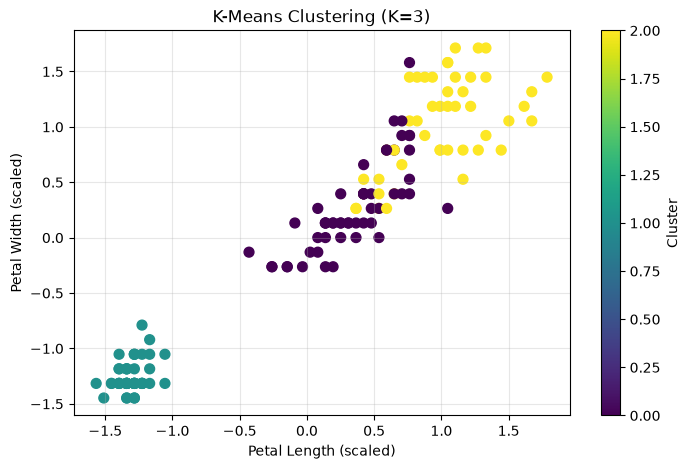

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Petal Length (scaled)")
plt.ylabel("Petal Width (scaled)")
plt.title("K-Means Clustering (K=3)")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()


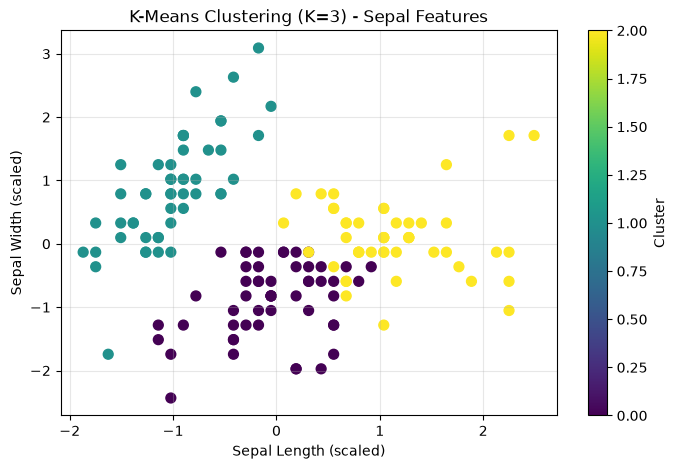

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length (scaled)")
plt.ylabel("Sepal Width (scaled)")
plt.title("K-Means Clustering (K=3) - Sepal Features")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>

مرحله دهم: مقایسه‌ی نتایج خوشه‌بندی بر اساس ویژگی‌های کاسبرگ و گلبرگ

در این مرحله، به‌منظور مقایسه‌ی تأثیر ویژگی‌های مختلف بر نمایش خوشه‌ها، دو نمودار پراکندگی از نتایج الگوریتم K-Means با سه خوشه رسم شد. در نمودار اول، نمونه‌ها بر اساس طول کاسبرگ (Sepal Length) و عرض کاسبرگ (Sepal Width) و در نمودار دوم، بر اساس طول گلبرگ (Petal Length) و عرض گلبرگ (Petal Width) نمایش داده شدند. در هر دو نمودار، از برچسب‌های خوشه‌ای به‌دست‌آمده از اجرای الگوریتم استفاده شد.

با بررسی نمودار ویژگی‌های کاسبرگ، مشاهده شد که خوشه‌ها جدایی کاملی از یکدیگر ندارند و به‌ویژه در نواحی میانی نمودار، هم‌پوشانی قابل‌توجهی بین نمونه‌های خوشه‌های مختلف وجود دارد. این موضوع نشان می‌دهد که نمایش داده‌ها بر اساس طول و عرض کاسبرگ، تفکیک بصری روشنی بین تمام خوشه‌ها ایجاد نمی‌کند.

در مقابل، در نمودار ویژگی‌های گلبرگ، خوشه‌ی نمایش‌داده‌شده با رنگ آبی‌ـ‌سبز از دو خوشه‌ی دیگر جدایی مشخص‌تری دارد. بااین‌حال، بین دو خوشه‌ی دیگر، به‌ویژه در ناحیه‌ی میانی نمودار، مقداری هم‌پوشانی مشاهده می‌شود. بنابراین، ویژگی‌های طول و عرض گلبرگ در مقایسه با ویژگی‌های کاسبرگ، جدایی بصری بهتری بین خوشه‌ها ایجاد می‌کنند.

در مجموع، مقایسه‌ی این دو نمودار نشان می‌دهد که ویژگی‌های گلبرگ اطلاعات متمایزکننده‌تری برای نمایش ساختار خوشه‌ها در مجموعه‌داده‌ی Iris فراهم می‌کنند. در مقابل، هم‌پوشانی بیشتر در نمودار ویژگی‌های کاسبرگ بیانگر محدودیت این دو ویژگی در جداسازی بصری خوشه‌هاست. لازم به ذکر است که الگوریتم K-Means در هر دو نمودار با استفاده از هر چهار ویژگی مقیاس‌بندی‌شده اجرا شده و نمودارها صرفاً نمایش دوبعدی نتایج یک خوشه‌بندی واحد هستند.

</div>

In [35]:

from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", score)


Silhouette Score: 0.45994823920518635


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله یازدهم: ارزیابی کیفیت خوشه‌بندی با استفاده از Silhouette Score

پس از اجرای الگوریتم K-Means و اختصاص نمونه‌ها به سه خوشه، به‌منظور ارزیابی کیفیت خوشه‌بندی از معیار Silhouette Score استفاده شد. این معیار میزان نزدیکی هر نمونه به خوشه‌ی خودش را در مقایسه با خوشه‌های دیگر بررسی می‌کند و مقداری بین ۱- و ۱+ دارد.

مقدار Silhouette Score محاسبه‌شده برابر با ۰٫۴۵۹۹ بود. این مقدار نشان می‌دهد که خوشه‌بندی انجام‌شده کیفیت متوسطی دارد؛ به این معنا که نمونه‌ها تا حد قابل‌قبولی در خوشه‌های خود قرار گرفته‌اند، اما جدایی کامل و مشخصی بین تمام خوشه‌ها وجود ندارد.

این نتیجه با نمودارهای پراکندگی بررسی‌شده نیز سازگار است؛ زیرا در نمودار ویژگی‌های گلبرگ، جدایی یکی از خوشه‌ها از دو خوشه‌ی دیگر بهتر مشاهده می‌شد، درحالی‌که بین دو خوشه‌ی دیگر هم‌پوشانی وجود داشت. بنابراین، اگرچه الگوریتم K-Means توانسته است ساختاری قابل‌قبول در داده‌ها ایجاد کند، همچنان امکان بهبود کیفیت خوشه‌بندی وجود دارد.

</div>

In [36]:
df_clustered = df.copy()
df_clustered["Cluster"] = clusters

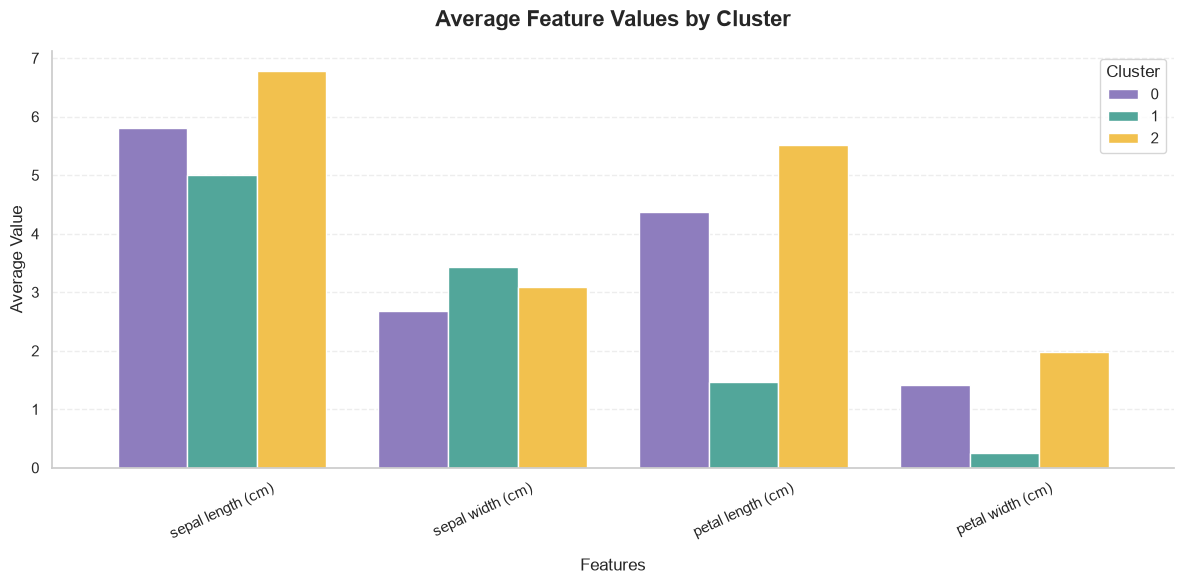

In [37]:

import matplotlib.pyplot as plt
import seaborn as sns

# محاسبه میانگین ویژگی‌ها در هر خوشه
cluster_means = df_clustered.groupby(
    "Cluster"
).mean(numeric_only=True)

# حذف ستون‌های غیرمرتبط با ویژگی‌های گل
cluster_means = cluster_means.drop(
    columns=["target", "species"],
    errors="ignore"
)

sns.set_theme(style="whitegrid", context="notebook")

ax = cluster_means.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
    color=["#8E7DBE", "#52A69A", "#F2C14E"],
    edgecolor="white",
    linewidth=1
)

ax.set_title(
    "Average Feature Values by Cluster",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Features", fontsize=12, labelpad=12)
ax.set_ylabel("Average Value", fontsize=12)
ax.legend(title="Cluster", frameon=True)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


مرحله دوازدهم: بررسی میانگین ویژگی‌ها در خوشه‌های تشکیل‌شده

در این مرحله، میانگین چهار ویژگی طول کاسبرگ (Sepal Length)، عرض کاسبرگ (Sepal Width)، طول گلبرگ (Petal Length) و عرض گلبرگ (Petal Width) برای هر یک از سه خوشه‌ی صفر، یک و دو محاسبه و در قالب نمودار میله‌ای مقایسه شد. هدف از این بررسی، شناخت ویژگی‌های غالب هر خوشه و مقایسه‌ی الگوی توزیع ویژگی‌ها میان خوشه‌های ایجادشده توسط الگوریتم K-Means بود.

خوشه‌ی صفر: میانگین طول کاسبرگ در این خوشه حدود ۵٫۸ سانتی‌متر و میانگین عرض کاسبرگ حدود ۲٫۹ سانتی‌متر است. بنابراین، این خوشه نسبت به خوشه‌ی یک، طول کاسبرگ بیشتری دارد، اما عرض کاسبرگ آن کمتر است. میانگین طول و عرض گلبرگ نیز در این خوشه از خوشه‌ی یک بیشتر است.

خوشه‌ی یک: میانگین طول کاسبرگ در این خوشه حدود ۵ سانتی‌متر و میانگین عرض کاسبرگ حدود ۳٫۵ سانتی‌متر است. در مقایسه با دو خوشه‌ی دیگر، این خوشه کمترین میانگین طول کاسبرگ را دارد، اما میانگین عرض کاسبرگ آن بیشتر است. همچنین، میانگین طول و عرض گلبرگ در این خوشه کمترین مقدار را در میان سه خوشه نشان می‌دهد.

خوشه‌ی دو: میانگین طول کاسبرگ در این خوشه حدود ۶٫۸ سانتی‌متر و میانگین عرض کاسبرگ حدود ۳٫۳ سانتی‌متر است. این خوشه بیشترین میانگین طول کاسبرگ را دارد. میانگین طول و عرض گلبرگ نیز در این خوشه از دو خوشه‌ی دیگر بیشتر است که نشان‌دهنده‌ی بزرگ‌تر بودن این دو ویژگی در نمونه‌های این خوشه است.

جمع‌بندی: مقایسه‌ی میانگین ویژگی‌ها نشان می‌دهد که خوشه‌ی صفر از نظر طول کاسبرگ در وضعیت میانی قرار دارد، خوشه‌ی یک کمترین میانگین طول کاسبرگ و بیشترین میانگین عرض کاسبرگ را دارد و خوشه‌ی دو بیشترین میانگین طول کاسبرگ و بیشترین میانگین طول و عرض گلبرگ را نشان می‌دهد. این تفاوت‌ها بیانگر آن است که الگوریتم K-Means نمونه‌ها را بر اساس شباهت در الگوی ویژگی‌هایشان به سه گروه تقسیم کرده است.

</div>

Actual Species  setosa  versicolor  virginica
Cluster                                      
0                    0          39         14
1                   50           0          0
2                    0          11         36


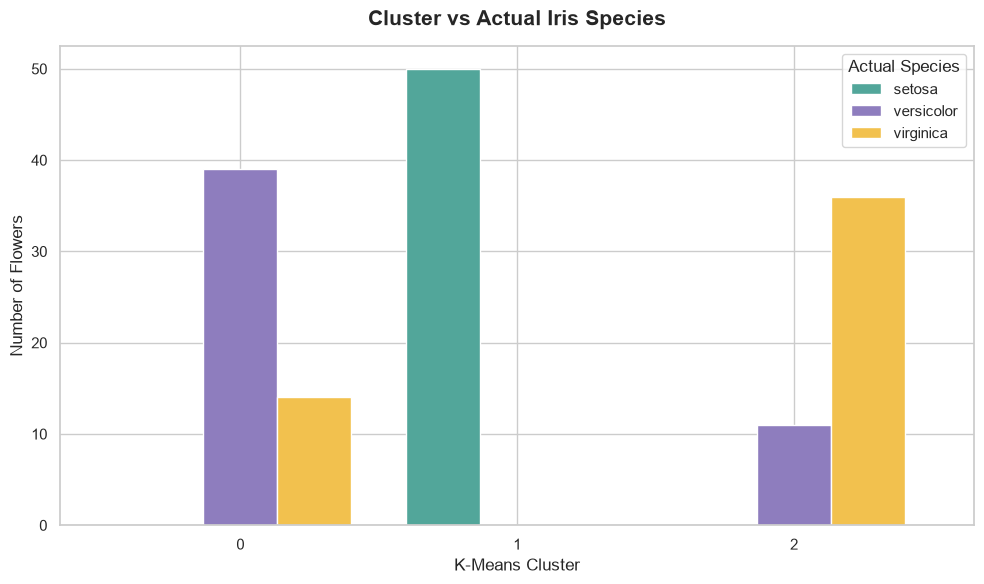

In [38]:

import pandas as pd
from sklearn.datasets import load_iris

# بارگذاری نام گونه‌های واقعی
iris = load_iris()

# مقایسه خوشه‌های پیش‌بینی‌شده با گونه‌های واقعی
comparison = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    pd.Series(
        [iris.target_names[i] for i in iris.target],
        name="Actual Species"
    )
)

print(comparison)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

comparison.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#52A69A", "#8E7DBE", "#F2C14E"],
    edgecolor="white",
    width=0.8
)

plt.title("Cluster vs Actual Iris Species",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("K-Means Cluster")
plt.ylabel("Number of Flowers")
plt.xticks(rotation=0)
plt.legend(title="Actual Species")
plt.tight_layout()
plt.show()


<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


### بررسی تعداد نمونه‌ها در خوشه‌ها
مرحله سیزدهم: بررسی تطابق خوشه‌های ایجادشده با گونه‌های واقعی

در این مرحله، به‌منظور ارزیابی عملکرد الگوریتم K-Means، برچسب خوشه‌های پیش‌بینی‌شده با گونه‌های واقعی مجموعه‌داده‌ی Iris مقایسه شد. هدف از این بررسی، مشخص‌کردن تعداد نمونه‌های متعلق به هر گونه در خوشه‌های صفر، یک و دو و ارزیابی میزان تفکیک گونه‌ها توسط الگوریتم بود. نتایج این مقایسه با استفاده از نمودار میله‌ای نیز نمایش داده شد.

خوشه‌ی صفر (Index 0): در این خوشه، ۳۹ نمونه از گونه‌ی Versicolor و ۱۴ نمونه از گونه‌ی Virginica قرار گرفتند. بنابراین، تعداد نمونه‌های Versicolor بیشتر است؛ بااین‌حال، حضور تعداد قابل‌توجهی از نمونه‌های Virginica نشان می‌دهد که این دو گونه در این خوشه به‌طور کامل از یکدیگر تفکیک نشده‌اند.

خوشه‌ی یک (Index 1): هر ۵۰ نمونه‌ی این خوشه متعلق به گونه‌ی Setosa هستند و هیچ نمونه‌ای از دو گونه‌ی Versicolor و Virginica در آن قرار نگرفته است. این نتیجه نشان می‌دهد که الگوریتم توانسته است نمونه‌های Setosa را به‌خوبی در یک خوشه‌ی مجزا قرار دهد.

خوشه‌ی دو (Index 2): در این خوشه، ۱۱ نمونه از گونه‌ی Versicolor و ۳۶ نمونه از گونه‌ی Virginica قرار دارند. بنابراین، گونه‌ی Virginica بیشترین تعداد نمونه را در این خوشه دارد؛ اما حضور نمونه‌های Versicolor نشان می‌دهد که جداسازی این دو گونه همچنان کامل نیست.

جمع‌بندی

نتایج نشان می‌دهد که الگوریتم K-Means در جداسازی گونه‌ی Setosa عملکرد بسیار خوبی داشته است؛ به‌طوری‌که تمام ۵۰ نمونه‌ی این گونه در خوشه‌ی یک قرار گرفته‌اند. در مقابل، نمونه‌های دو گونه‌ی Versicolor و Virginica بین خوشه‌های صفر و دو توزیع شده‌اند و بخشی از آن‌ها در یک خوشه مشترک قرار گرفته‌اند. این موضوع بیانگر شباهت بیشتر ویژگی‌های این دو گونه و دشوارتر بودن تفکیک آن‌ها با استفاده از الگوریتم K-Means است.

در مجموع، خوشه‌بندی انجام‌شده توانسته است گونه‌ی Setosa را به‌خوبی از دو گونه‌ی دیگر جدا کند، اما در تفکیک کامل Versicolor و Virginica محدودیت‌هایی دارد. این نتیجه با بررسی‌های بصری پیشین نیز هم‌خوانی دارد؛ زیرا در نمودارهای خوشه‌بندی، هم‌پوشانی بیشتری بین دو گروه مربوط به این گونه‌ها مشاهده شده بود.

</div>

<div class="iris-md-card" dir="rtl" style="text-align: right; box-sizing: border-box; max-width: 100%; overflow-wrap: anywhere;">
<style>
.iris-md-card { box-sizing:border-box; direction:rtl; text-align:right; max-width:100%; width:100%; overflow-wrap:anywhere; word-break:normal; white-space:normal; padding:24px 26px; margin:14px 0 22px; border:1px solid #dbe5f2; border-right:5px solid #6486c5; border-radius:18px; background:linear-gradient(135deg,#ffffff 0%,#f7f9ff 100%); color:#263449; font-family:Vazirmatn,Tahoma,Arial,sans-serif; font-size:15px; line-height:2.05; box-shadow:0 5px 18px rgba(40,65,110,.08); }
.iris-md-card h1,.iris-md-card h2,.iris-md-card h3,.iris-md-card h4 { direction:rtl; text-align:right; color:#294c83; line-height:1.8; overflow-wrap:anywhere; margin:1.15em 0 .65em; padding:9px 14px; border-radius:10px; background:linear-gradient(90deg,#edf3ff,#e4edff); border-right:4px solid #6c8ed0; }
.iris-md-card h1 {font-size:1.65em}.iris-md-card h2 {font-size:1.4em}.iris-md-card h3 {font-size:1.2em}
.iris-md-card p {margin:.7em 0 1em; text-align:justify; text-justify:inter-word; overflow-wrap:anywhere;}
.iris-md-card ul,.iris-md-card ol {padding-right:1.8em; padding-left:.6em; margin:.5em 0 1.1em;}
.iris-md-card li {padding:3px 2px; margin:4px 0; overflow-wrap:anywhere;}
.iris-md-card li::marker {color:#6688c8; font-weight:bold;}
.iris-md-card strong {color:#244f91; background:#edf3ff; border-radius:5px; padding:0 3px;}
.iris-md-card em {color:#536fa3;}
.iris-md-card code {direction:ltr; unicode-bidi:embed; display:inline-block; max-width:100%; overflow-wrap:anywhere; white-space:pre-wrap; padding:2px 7px; margin:0 2px; border-radius:6px; background:#eaf0fa; color:#315a91; border:1px solid #d6e1f2; font-size:.92em;}
.iris-md-card blockquote {margin:1em 0; padding:10px 16px; border-right:4px solid #8ca6d6; border-left:0; border-radius:9px; background:#f0f5ff; color:#405574;}
.iris-md-card table {display:block; max-width:100%; overflow-x:auto; border-collapse:separate; border-spacing:0; border:1px solid #d8e2f0; border-radius:12px; margin:1em 0; direction:rtl;}
.iris-md-card th {background:#dfeaff; color:#294c83; font-weight:700;}
.iris-md-card th,.iris-md-card td {padding:9px 13px; border-bottom:1px solid #e3eaf4; text-align:right; white-space:normal;}
.iris-md-card tr:nth-child(even) td {background:#f5f8fd;}
.iris-md-card tr:last-child td {border-bottom:0;}
.iris-md-card hr {border:0; border-top:1px solid #dce5f2; margin:1.5em 0;}
@media (max-width:600px) {.iris-md-card {padding:16px 14px; border-radius:13px; font-size:14px;} .iris-md-card h1 {font-size:1.4em}.iris-md-card h2 {font-size:1.25em}}
</style>


نتیجه‌گیری نهایی

در این پروژه، مجموعه‌داده‌ی Iris با استفاده از روش‌های مختلف تحلیل اکتشافی داده‌ها (EDA) بررسی شد. ابتدا ویژگی‌های آماری داده‌ها و نمونه‌های پرت شناسایی شدند. سپس، با استفاده از نمودارهای پراکندگی، تحلیل همبستگی و نمودارهای حرارتی، روابط بین طول و عرض کاسبرگ و گلبرگ در سه گونه‌ی Setosa، Versicolor و Virginica مورد بررسی قرار گرفت.

نتایج تحلیل‌ها نشان داد که ویژگی‌های گلبرگ، به‌ویژه طول و عرض گلبرگ، در مقایسه با ویژگی‌های کاسبرگ، اطلاعات متمایزکننده‌تری برای تفکیک گونه‌ها فراهم می‌کنند. همچنین، شدت همبستگی بین ویژگی‌ها در گونه‌های مختلف یکسان نبود و بسته به نوع ویژگی و گونه تغییر می‌کرد.

در ادامه، پس از مقیاس‌بندی چهار ویژگی، الگوریتم K-Means با سه خوشه اجرا شد. تعداد نمونه‌های اختصاص‌یافته به خوشه‌های صفر، یک و دو به‌ترتیب برابر با ۵۳، ۵۰ و ۴۷ نمونه بود. نمودارهای خوشه‌بندی نشان دادند که یکی از خوشه‌ها جدایی مشخص‌تری دارد، درحالی‌که بین دو خوشه‌ی دیگر هم‌پوشانی مشاهده می‌شود. مقدار Silhouette Score برابر با ۰٫۴۵۹۹ نیز نشان داد که خوشه‌بندی انجام‌شده کیفیت متوسط و قابل‌قبولی دارد، اما جدایی کامل بین تمام خوشه‌ها حاصل نشده است.

مقایسه‌ی برچسب‌های خوشه‌ها با گونه‌های واقعی نشان داد که هر ۵۰ نمونه‌ی Setosa در یک خوشه قرار گرفته‌اند؛ در مقابل، نمونه‌های Versicolor و Virginica بین دو خوشه‌ی دیگر توزیع شده‌اند. این نتیجه نشان می‌دهد که الگوریتم K-Means در تفکیک Setosa عملکرد مناسبی داشته، اما جداسازی کامل دو گونه‌ی Versicolor و Virginica دشوارتر بوده است.

در مجموع، این پروژه نشان داد که تحلیل اکتشافی داده‌ها، بررسی همبستگی ویژگی‌ها و استفاده از روش‌های خوشه‌بندی می‌توانند به شناسایی الگوها و روابط موجود در داده‌ها کمک کنند. همچنین، نتایج تأکید می‌کنند که انتخاب ویژگی‌های مناسب و ارزیابی دقیق خروجی الگوریتم، نقش مهمی در تفسیر صحیح نتایج تحلیل داده‌ها دارند.
</div>